# Freight rate prediction

Predict the posted rate (USD) of a freight load from its route, distance, equipment, weight and pickup date. The model is trained on `train-test.csv` (Jan-Oct, labelled) and used on `validation.csv` (Nov-Dec, no labels).

**Outputs of this notebook**

| File | Content |
|---|---|
| `validation_predictions.csv` | `load_id`, `predicted_rate` for the 12,000 validation loads |
| `december_predictions.csv` | predictions for the fixed December route (Lexington to Fort Wayne) |
| `scorer_results/candidate_december.png` | December chart produced by `score.py` |
| `freight_rate_model.joblib` | final fitted pipeline (preprocessing and CatBoost), see the export section |

**How to run**

1. Install the dependencies: `pip install -r requirements.txt`
2. Keep the provided data files and `score.py` in the same folder as the notebook.
3. Run all cells from top to bottom. The hyperparameter search takes about 35 minutes, the rest a few minutes. Seeds are fixed.

**Contents**

| Section | Question |
|---|---|
| Data exploration, preprocessing | What is in the data and what needs cleaning? |
| Time-ordered split and cross-validation | How is performance measured without looking into the future? |
| Baselines, error analysis, price outliers | Where does the error come from, and which metric to trust? |
| quote_signal and market_index | Which features keep a stable relation with the price? |
| Final model, tuning, held-out test | Which model, which settings, and how well does it do on unseen months? |
| Predictions and December chart | Final files for the evaluator |

**Approach in short**

- Validation follows time: Jan-Aug is the dev part, Sep-Oct is held out and used once. Cross-validation folds are 2-month windows moving forward, each trained on all the earlier data.
- Anything learned from data (medians, fitted models) is fitted on the training fold only.
- MAE is the main metric. About 1.4% of the prices are random outliers that cannot be predicted, and they dominate RMSE.
- `quote_signal` is removed because its relation with the price changes sign from month to month. `market_index` is kept.
- Final model: CatBoost, l1 loss, rate-per-mile target, retrained on all labelled data before predicting `validation.csv`.

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data exploration

In [2]:
# Load the training and validation files
train_test_df = pd.read_csv("train-test.csv")
val_df = pd.read_csv("validation.csv")

In [3]:
# First rows
train_test_df.head(15)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28
5,TR-000006,Phoenix,Corpus Christi,28.75668,-115.87725,28.61374,-95.89569,1396.4,Flatbed,17018.0,2025-01-01,0.95167,1.92983,2676.98
6,TR-000007,Fresno,San Antonio,33.07921,-119.79528,29.50969,-98.40059,1502.6,Dry Van,19112.0,2025-01-01,0.95696,1.82074,2718.54
7,TR-000008,San Francisco,Kansas City,35.19670,-121.69849,39.41104,-91.12450,1976.9,Dry Van,29169.0,2025-01-01,0.97818,1.78430,3522.92
8,TR-000009,Bakersfield,Montgomery,33.28832,-116.67935,31.37602,-86.10743,2027.7,Dry Van,35018.0,2025-01-01,0.96534,1.79522,3675.27
9,TR-000010,Albuquerque,Phoenix,35.39918,-109.59792,28.75668,-115.87725,717.1,Flatbed,34671.0,2025-01-01,0.98475,2.17079,1578.83


In [4]:
# Column types and non-null counts
train_test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [5]:
# Summary statistics
train_test_df.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


In [6]:
# Missing values per column
train_test_df.isna().sum()

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

In [7]:
# Share of missing values per column
train_test_df.isna().sum() / train_test_df.shape[0]

load_id         0.000000
pickup          0.000000
delivery        0.000000
pickup_lat      0.000000
pickup_lon      0.000000
delivery_lat    0.000000
delivery_lon    0.000000
distance        0.000000
equipment       0.000000
weight          0.006250
date            0.000000
market_index    0.007792
quote_signal    0.000000
posted_rate     0.000000
dtype: float64

In [8]:
# Duplicate rows
train_test_df.duplicated().sum()

np.int64(0)

In [9]:
# Number of distinct values per column
train_test_df.nunique()

load_id         48000
pickup             64
delivery           64
pickup_lat         64
pickup_lon         63
delivery_lat       64
delivery_lon       63
distance        21204
equipment           3
weight          23678
date              304
market_index    32884
quote_signal    37633
posted_rate     45398
dtype: int64

In [53]:
# Rows with at least one missing value
missing_data = train_test_df[train_test_df.isna().any(axis=1)]
missing_data.head(10)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
116,TR-000117,Memphis,Fort Wayne,35.56802,-89.52871,41.31561,-85.36206,533.8,Reefer,30570.0,2025-01-01,NaN,2.37177,1271.10
226,TR-000227,Tampa,Hartford,28.35765,-86.94782,39.55328,-72.18051,1342.7,Reefer,26397.0,2025-01-02,NaN,2.01837,2743.13
311,TR-000312,Los Angeles,New York,28.56624,-116.70249,40.00674,-73.79840,2935.7,Flatbed,32807.0,2025-01-02,NaN,1.91236,5568.57
323,TR-000324,Richmond,San Francisco,38.09122,-76.78906,35.19670,-121.69849,2848.8,Reefer,NaN,2025-01-03,0.91370,1.92679,5430.07
511,TR-000512,Grand Rapids,Amarillo,43.43800,-86.29173,33.17137,-104.36789,1420.7,Reefer,19360.0,2025-01-04,NaN,1.94596,2786.63
531,TR-000532,Richmond,San Antonio,38.09122,-76.78906,29.50969,-98.40059,1624.7,Reefer,39452.0,2025-01-04,NaN,2.04970,3295.80
629,TR-000630,Birmingham,Fort Wayne,33.45794,-86.72789,41.31561,-85.36206,648.1,Dry Van,23236.0,2025-01-05,NaN,1.93237,1256.20
644,TR-000645,Lubbock,Milwaukee,29.87534,-99.85456,39.62180,-88.48008,1089.3,Dry Van,40473.0,2025-01-05,NaN,2.04466,2171.37
648,TR-000649,Tulsa,Mobile,33.45894,-94.78556,31.80442,-88.25195,467.0,Reefer,NaN,2025-01-05,0.77536,2.48162,1178.03
694,TR-000695,Los Angeles,Fresno,28.56624,-116.70249,33.07921,-119.79528,432.6,Reefer,NaN,2025-01-05,0.84069,2.37036,1022.13


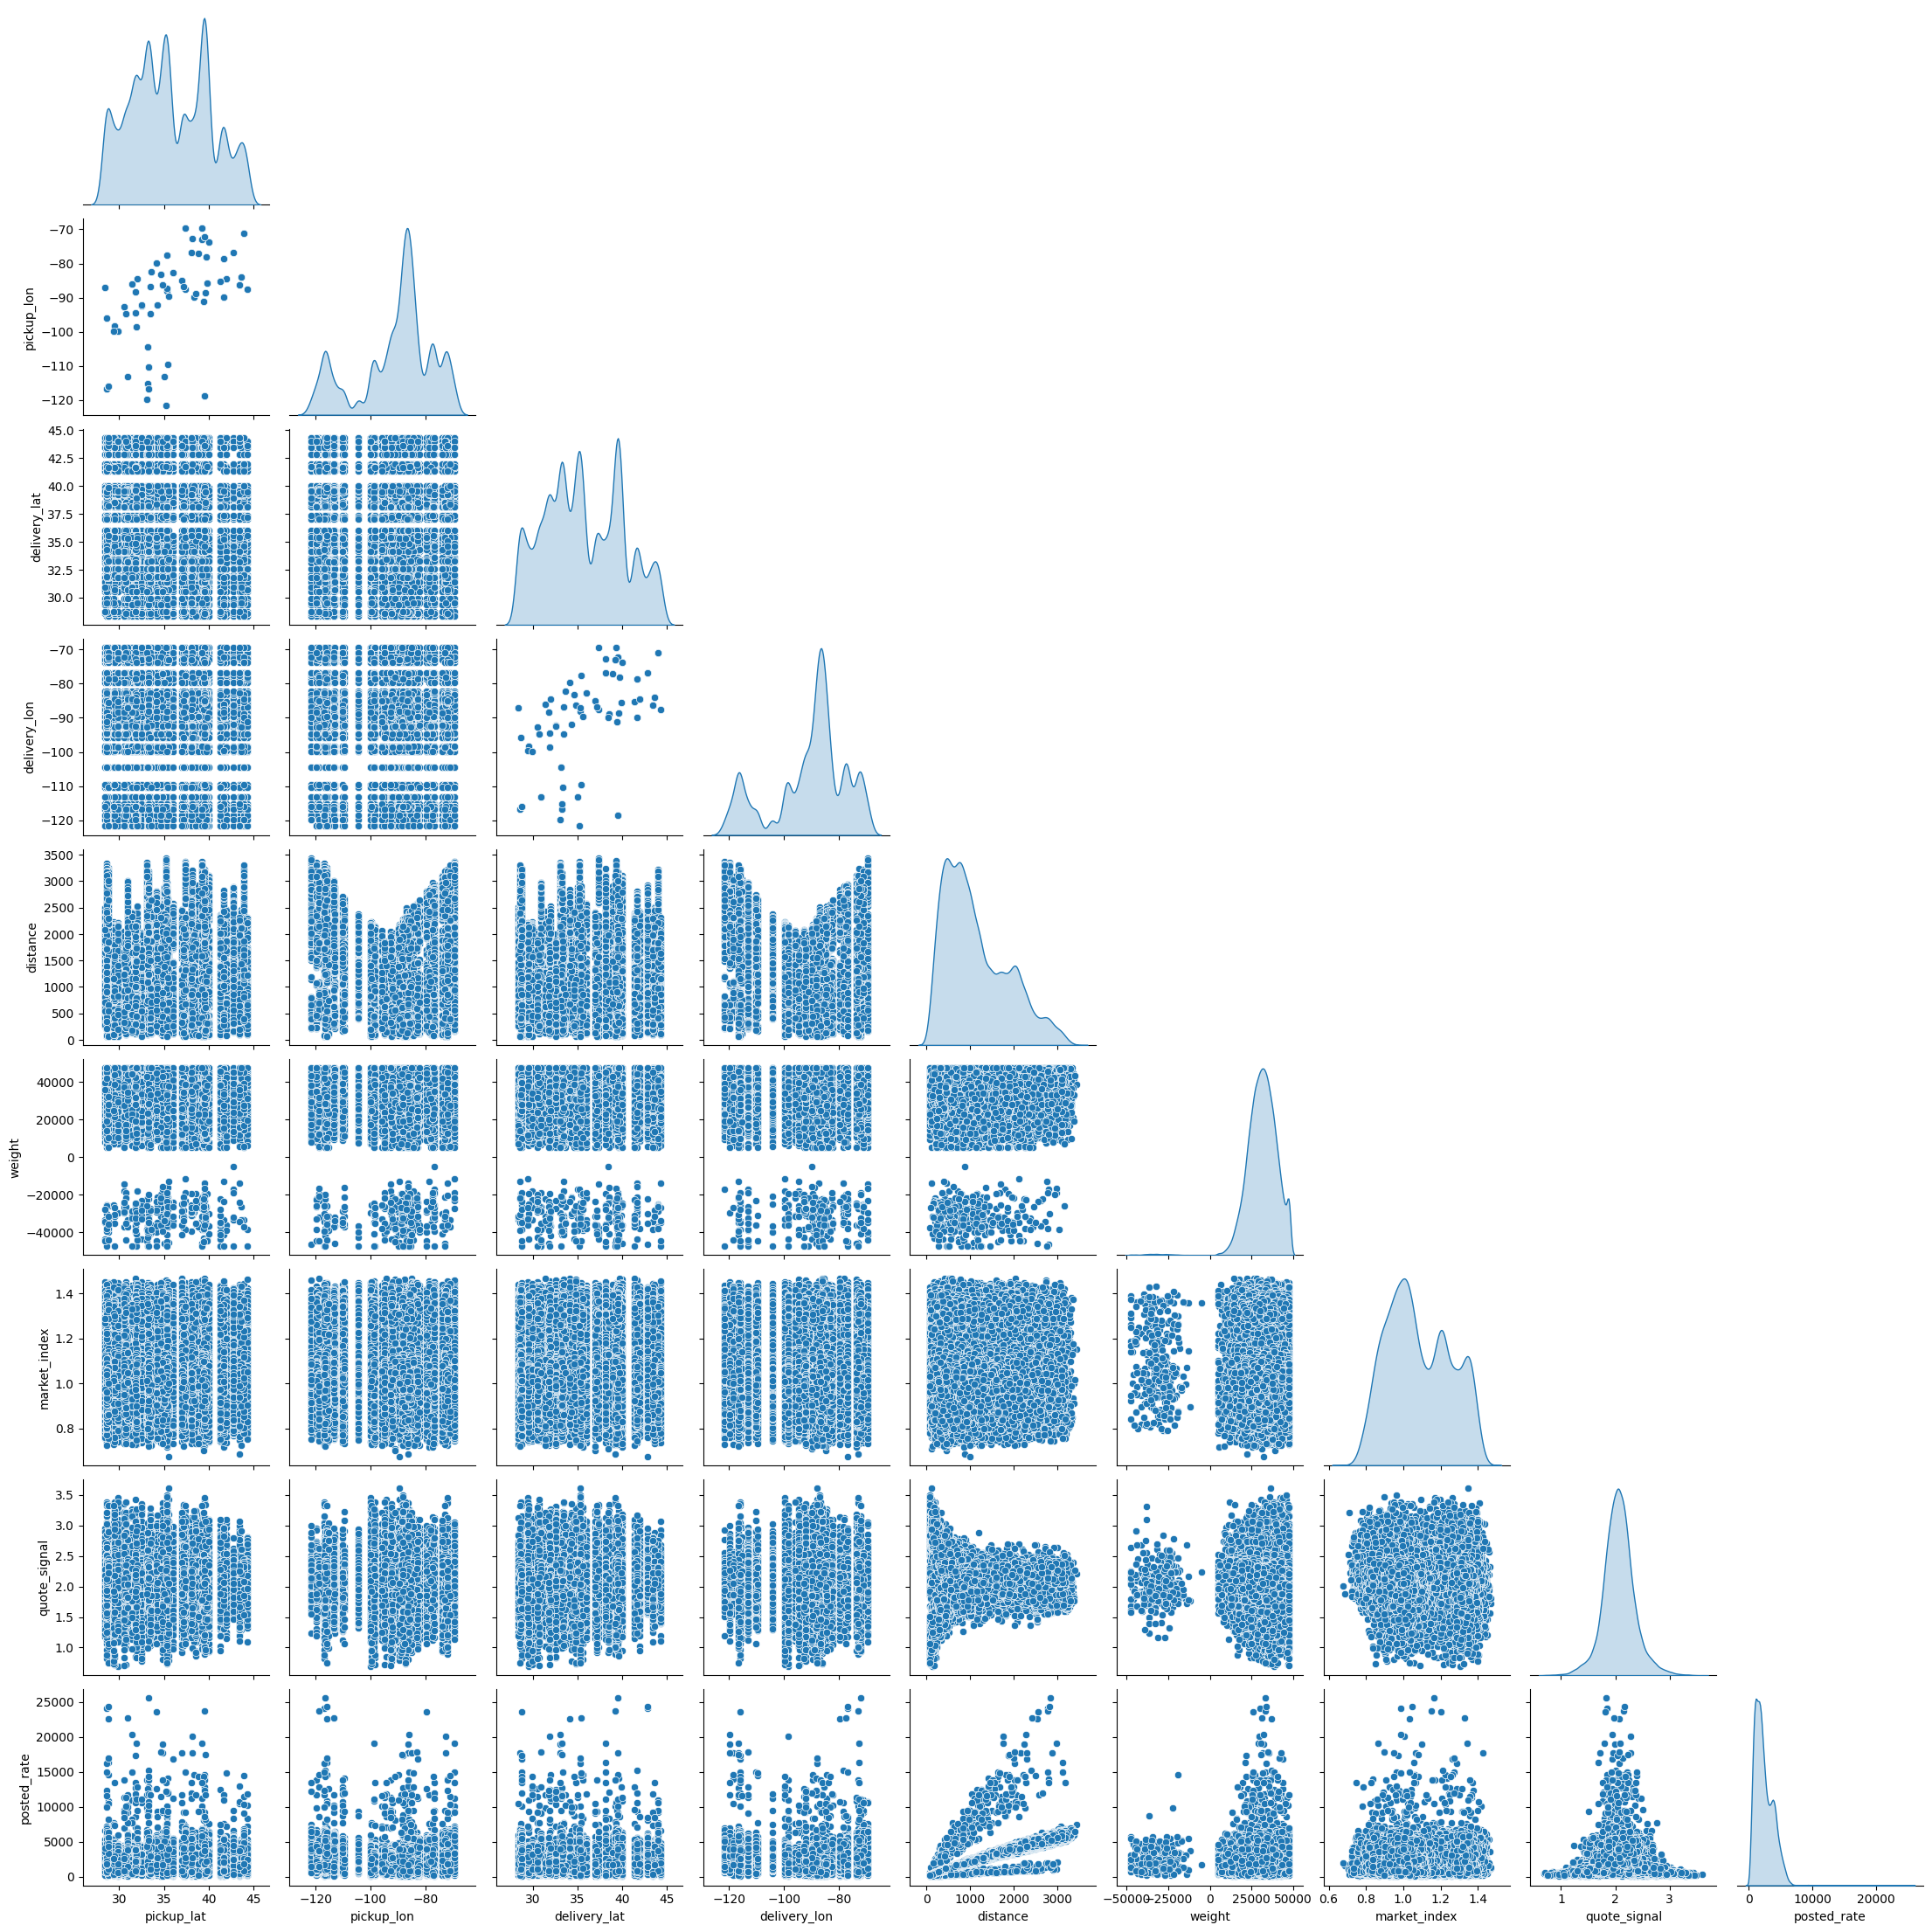

In [11]:
# Pairwise distributions
sns.pairplot(train_test_df,  diag_kind="kde", corner=True)

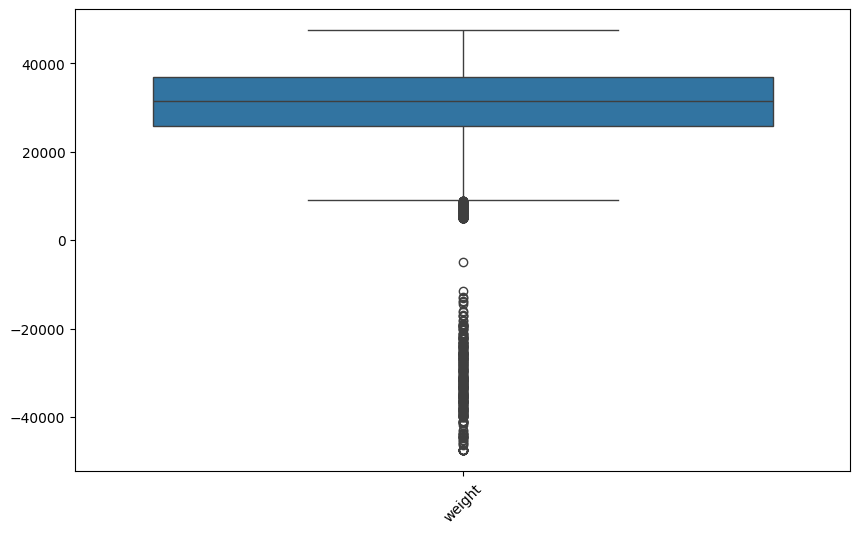

In [12]:
# Weight distribution
plt.figure(figsize=(10, 6))
sns.boxplot(data=train_test_df[["weight"]])
plt.xticks(rotation=45)
plt.show()

In [13]:
# Correlation matrix
corr = train_test_df.corr(numeric_only = True)

<Axes: >

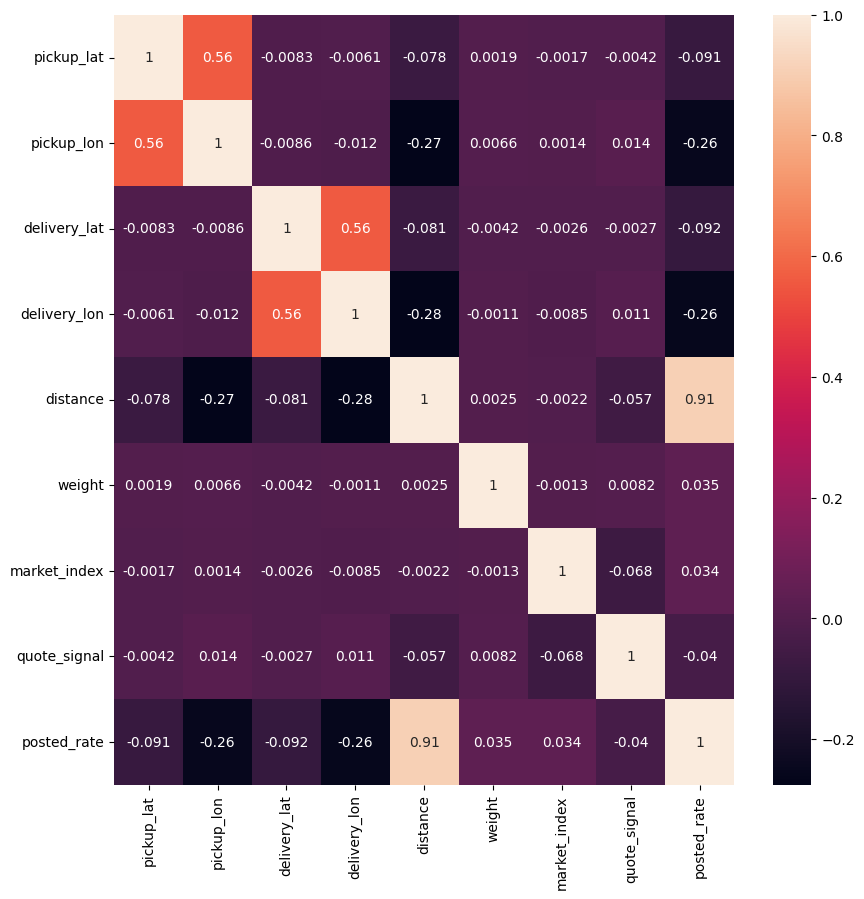

In [14]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(10,10))
sns.heatmap(corr, annot=True)

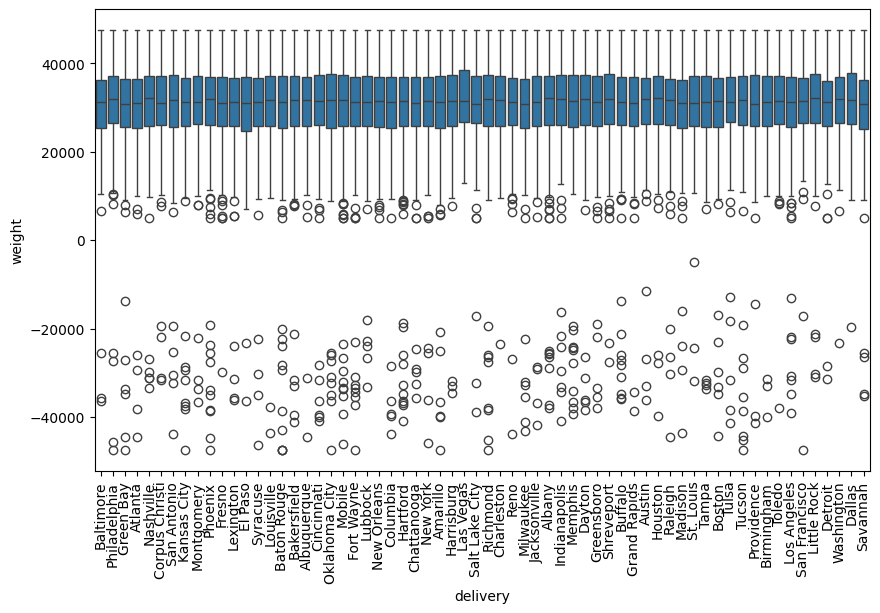

In [54]:
# Weight by delivery city
plt.figure(figsize=(10, 6))
sns.boxplot(data=train_test_df, x="delivery", y="weight")
plt.xticks(rotation=90)
plt.show()

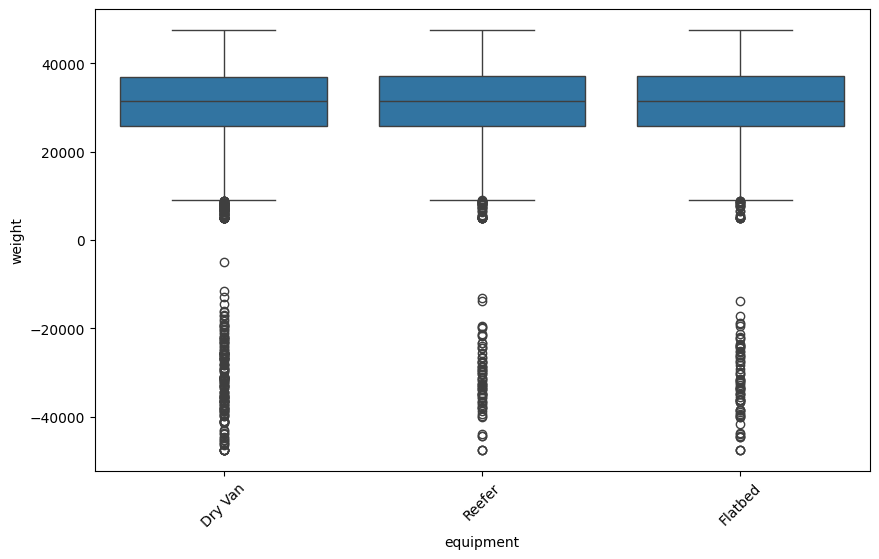

In [16]:
# Weight by equipment
plt.figure(figsize=(10, 6))
sns.boxplot(data=train_test_df, x="equipment", y="weight")
plt.xticks(rotation=45)
plt.show()

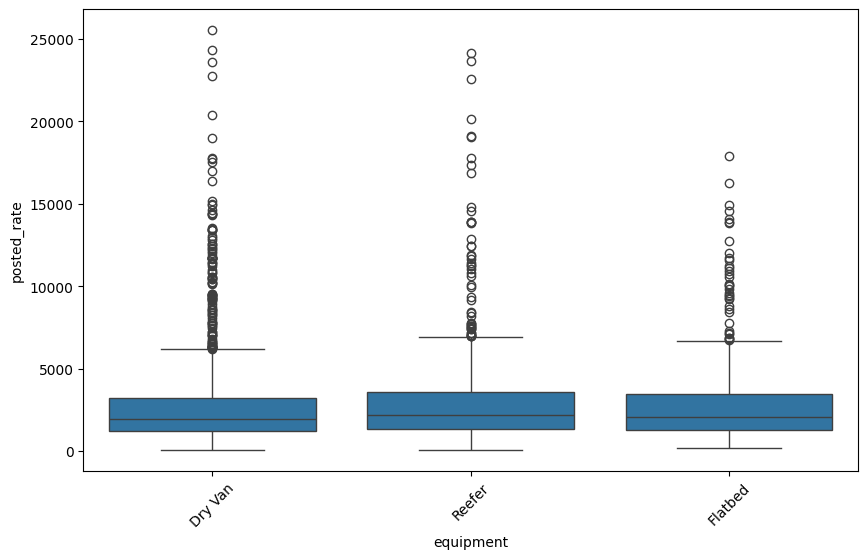

In [17]:
# Posted rate by equipment
plt.figure(figsize=(10, 6))
sns.boxplot(data=train_test_df, x="equipment", y="posted_rate")
plt.xticks(rotation=45)
plt.show()

In [18]:
# Number of positive and negative weights
print(train_test_df[train_test_df["weight"] > 0].shape[0])
print(train_test_df[train_test_df["weight"] < 0].shape[0])

47408
292


## Preprocessing

In [19]:
# Cleaning step: negative weights become positive
from sklearn.preprocessing import FunctionTransformer


def cleaning(df):
     df = df.copy()
     df["weight"] = df["weight"].abs()
     return df
clean_tf = FunctionTransformer(cleaning)

In [20]:
# Imputation step: the values are learned on the training data only
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted


class MyStatefulTransformer(BaseEstimator, TransformerMixin):
    """Fill missing values with statistics learned on the training data.

    fit       -> learns the median weight and the global median market_index
    transform -> fills weight with its median; fills market_index with the median
                 of the same date, then with the global median
    """

    def __init__(self):
        pass
    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()

        self.median_ = X["weight"].median()
        self.median_marketindex_ = X["market_index"].median()


        return self

    def transform(self, X):
        check_is_fitted(self, "median_")
        X = pd.DataFrame(X).copy()            

        X["weight"] = X["weight"].fillna(self.median_)
        date_median  = X.groupby("date")["market_index"].transform("median")

        X["market_index"] = (X["market_index"]
                             .fillna(date_median)
                             .fillna(self.median_marketindex_))
        return X

In [21]:
# Full preprocessing pipeline: cleaning, imputation, encoding
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline


num_cols = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
            "distance", "weight", "market_index", "quote_signal"]
cat_cols = ["equipment"]

encode = ColumnTransformer(
    [("num", "passthrough", num_cols),
     ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)],
    remainder="drop",
    verbose_feature_names_out=False,
)
encode.set_output(transform="pandas")

pipe = Pipeline([
    ("clean", clean_tf),
    ("impute", MyStatefulTransformer()),
    ("encode", encode),
])

In [22]:
# Baseline model: price = median rate per mile x distance
from sklearn.base import BaseEstimator, RegressorMixin


class RatePerMile(BaseEstimator, RegressorMixin):
    """price = median rate-per-mile learned on train x distance (optionally per equipment)."""

    def __init__(self, by_equipment=False):
        self.by_equipment = by_equipment

    def fit(self, X, y):
        rpm = y / X["distance"]
        self.global_rpm_ = rpm.median()
        if self.by_equipment:
            self.rpm_by_eq_ = rpm.groupby(X["equipment"]).median()
        return self

    def predict(self, X):
        rpm = self.global_rpm_
        if self.by_equipment:
            rpm = X["equipment"].map(self.rpm_by_eq_).fillna(self.global_rpm_)
        return (rpm * X["distance"]).to_numpy()

In [23]:
# First model: linear regression on the preprocessing pipeline
from sklearn.linear_model import LinearRegression

model_pipe = Pipeline([("prep", pipe), ("model", LinearRegression())])

## Time-ordered split and cross-validation

The last two months (Sep-Oct) are kept as a held-out test. On the dev part (Jan-Aug), validation windows of two months move forward and each model is trained on all the data before the window, capped at six months. The three folds train on two, four and six months.

In [24]:
# Hold out the last two months as the final test, the rest is the dev part
df = train_test_df.sort_values("date").reset_index(drop=True)
df["date"] = pd.to_datetime(df["date"])

cutoff = df["date"].max() - pd.DateOffset(months=2)
dev  = df[df["date"] <= cutoff].reset_index(drop=True)
test = df[df["date"] >  cutoff].reset_index(drop=True)

X_dev,  y_dev  = dev.drop(columns="posted_rate"),  dev["posted_rate"]
X_test, y_test = test.drop(columns="posted_rate"), test["posted_rate"]

In [25]:
# Time-ordered folds: two-month validation windows, trained on all the earlier data (at most six months)
def make_time_splits(dates, n_splits=4, val_months=2, train_months=None, gap_days=0):
    """Validation windows of `val_months`, moving back from the end of dev.
    train_months=None -> expanding window (all past data)
    train_months=6    -> sliding window (only the last 6 months before validation)
    gap_days          -> optional gap between train and validation
    """
    dates = pd.to_datetime(pd.Series(dates).reset_index(drop=True))
    end = dates.max() + pd.Timedelta(days=1)          # exclusive end
    splits = []
    for k in range(n_splits, 0, -1):                  # earliest fold first
        val_end   = end - pd.DateOffset(months=val_months * (k - 1))
        val_start = val_end - pd.DateOffset(months=val_months)
        train_end = val_start - pd.Timedelta(days=gap_days)
        train_start = (train_end - pd.DateOffset(months=train_months)
                       if train_months else dates.min())

        tr = np.where((dates >= train_start) & (dates < train_end))[0]
        va = np.where((dates >= val_start)   & (dates < val_end))[0]
        if len(tr) and len(va):
            splits.append((tr, va))
    return splits

splits = make_time_splits(X_dev["date"], n_splits=4, val_months=2, train_months=6)

In [26]:
# Dates and size of each fold
for i, (tr, va) in enumerate(splits):
    d = X_dev["date"]
    print(f"fold {i}: train {d.iloc[tr].min().date()} -> {d.iloc[tr].max().date()} ({len(tr)} rows) | "
          f"val {d.iloc[va].min().date()} -> {d.iloc[va].max().date()} ({len(va)} rows)")

fold 0: train 2025-01-01 -> 2025-02-28 (9255 rows) | val 2025-03-01 -> 2025-04-30 (9855 rows)
fold 1: train 2025-01-01 -> 2025-04-30 (19110 rows) | val 2025-05-01 -> 2025-06-30 (9696 rows)
fold 2: train 2025-01-01 -> 2025-06-30 (28806 rows) | val 2025-07-01 -> 2025-08-31 (9671 rows)


## Baselines and candidate models

All models are compared on the same time-ordered folds.

In [27]:
# Cross-validate the linear model on the time-ordered folds
from sklearn.model_selection import cross_validate

scoring = {
    "mae":  "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "mape": "neg_mean_absolute_percentage_error",
}
res = cross_validate(model_pipe, X_dev, y_dev, cv=splits,
                     scoring=scoring, return_train_score=True)

for i in range(len(splits)):
    print(f"fold {i} | "
          f"val   MAE {-res['test_mae'][i]:8.1f}  RMSE {-res['test_rmse'][i]:8.1f}  MAPE {-res['test_mape'][i]:.3f} | "
          f"train MAE {-res['train_mae'][i]:8.1f}  RMSE {-res['train_rmse'][i]:8.1f}  MAPE {-res['train_mape'][i]:.3f}")

print("mean val | "
      f"MAE {-res['test_mae'].mean():.1f}  RMSE {-res['test_rmse'].mean():.1f}  MAPE {-res['test_mape'].mean():.3f}")


fold 0 | val   MAE    175.4  RMSE    559.5  MAPE 0.123 | train MAE    123.7  RMSE    542.2  MAPE 0.074
fold 1 | val   MAE    158.4  RMSE    644.6  MAPE 0.093 | train MAE    130.2  RMSE    542.0  MAPE 0.082
fold 2 | val   MAE    139.9  RMSE    629.3  MAPE 0.078 | train MAE    140.3  RMSE    577.4  MAPE 0.085
mean val | MAE 157.9  RMSE 611.1  MAPE 0.098


In [28]:
# Compare all candidate models on the same folds, with raw and log targets
import time
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import cross_validate


def build(model, scale=False, log_target=False):
    steps = [("prep", clone(pipe))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    est = Pipeline(steps)
    if log_target:
        est = TransformedTargetRegressor(regressor=est, func=np.log1p, inverse_func=np.expm1)
    return est


SEED = 42
candidates = {
    "Linear":       (lambda: LinearRegression(), False),
    "Ridge":        (lambda: Ridge(alpha=1.0), True),
    "RandomForest": (lambda: RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED), False),
    "ExtraTrees":   (lambda: ExtraTreesRegressor(n_estimators=200, n_jobs=-1, random_state=SEED), False),
    "HistGB":       (lambda: HistGradientBoostingRegressor(random_state=SEED), False),
    "XGBoost":      (lambda: XGBRegressor(n_estimators=400, learning_rate=0.05, n_jobs=-1, random_state=SEED), False),
    "LightGBM":     (lambda: LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=SEED, verbose=-1), False),
    "CatBoost":     (lambda: CatBoostRegressor(iterations=500, learning_rate=0.05, random_seed=SEED, verbose=0), False),
}

models = {"Dummy (median)": build(DummyRegressor(strategy="median"))}
models["Baseline: rate/mile (global)"]       = RatePerMile()
models["Baseline: rate/mile (by equipment)"] = RatePerMile(by_equipment=True)
for name, (make, scale) in candidates.items():
    models[f"{name} | raw"] = build(make(), scale=scale, log_target=False)
    models[f"{name} | log"] = build(make(), scale=scale, log_target=True)
models["SVR | log"] = build(SVR(), scale=True, log_target=True)   # slow

scoring = {
    "mae":  "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "mape": "neg_mean_absolute_percentage_error",
}

rows = []
for name, est in models.items():
    t0 = time.time()
    try:
        r = cross_validate(est, X_dev, y_dev, cv=splits, scoring=scoring,
                           return_train_score=True, error_score="raise")
    except Exception as e:
        print(f"{name:<18} FAILED -> {type(e).__name__}: {str(e)[:150]}")
        continue
    for i in range(len(splits)):
        rows.append({
            "model": name, "fold": i,
            "val_mae":  -r["test_mae"][i],  "val_rmse":  -r["test_rmse"][i],  "val_mape":  -r["test_mape"][i],
            "train_mae": -r["train_mae"][i], "train_rmse": -r["train_rmse"][i], "train_mape": -r["train_mape"][i],
            "fit_time": r["fit_time"][i],
        })
    print(f"{name:<18} done in {time.time() - t0:5.0f}s | val MAE {-r['test_mae'].mean():7.1f}")

bench = pd.DataFrame(rows)
summary = (bench.groupby("model")[["val_mae", "val_rmse", "val_mape", "train_mae", "fit_time"]]
                .mean().sort_values("val_mae").round(3))
summary


Dummy (median)     done in     0s | val MAE  1143.6
Baseline: rate/mile (global) done in     0s | val MAE   239.2
Baseline: rate/mile (by equipment) done in     0s | val MAE   206.7
Linear | raw       done in     0s | val MAE   157.9
Linear | log       done in     0s | val MAE   651.8
Ridge | raw        done in     0s | val MAE   158.0
Ridge | log        done in     0s | val MAE   651.6
RandomForest | raw done in    26s | val MAE   236.9
RandomForest | log done in    22s | val MAE   198.4
ExtraTrees | raw   done in    14s | val MAE   167.3
ExtraTrees | log   done in    14s | val MAE   155.7
HistGB | raw       done in     4s | val MAE   173.5
HistGB | log       done in     1s | val MAE   149.1
XGBoost | raw      done in     3s | val MAE   282.9
XGBoost | log      done in     3s | val MAE   200.4
LightGBM | raw     done in     4s | val MAE   186.3
LightGBM | log     done in     3s | val MAE   151.6
CatBoost | raw     done in     7s | val MAE   162.7
CatBoost | log     done in     8s | va

,val_mae,val_rmse,val_mape,train_mae,fit_time
model,,,,,
CatBoost | log,132.736,609.214,0.060,87.991,2.607
HistGB | log,149.126,616.809,0.066,92.837,0.340
LightGBM | log,151.558,616.283,0.068,90.174,0.539
ExtraTrees | log,155.706,631.366,0.070,0.000,4.116
Linear | raw,157.888,611.103,0.098,131.420,0.022
Ridge | raw,158.006,611.162,0.098,131.425,0.027
CatBoost | raw,162.671,658.407,0.087,93.715,2.446
ExtraTrees | raw,167.267,658.009,0.077,0.000,4.058
HistGB | raw,173.544,640.569,0.081,109.011,1.388


In [29]:
# Add the two rate-per-mile baselines to the results
new_rows = []
for name, est in {"Baseline: rate/mile (global)": RatePerMile(),
                  "Baseline: rate/mile (by equipment)": RatePerMile(by_equipment=True)}.items():
    r = cross_validate(est, X_dev, y_dev, cv=splits, scoring=scoring,
                       return_train_score=True, error_score="raise")
    for i in range(len(splits)):
        new_rows.append({
            "model": name, "fold": i,
            "val_mae":  -r["test_mae"][i],  "val_rmse":  -r["test_rmse"][i],  "val_mape":  -r["test_mape"][i],
            "train_mae": -r["train_mae"][i], "train_rmse": -r["train_rmse"][i], "train_mape": -r["train_mape"][i],
            "fit_time": r["fit_time"][i],
        })

bench = pd.concat([bench, pd.DataFrame(new_rows)], ignore_index=True)

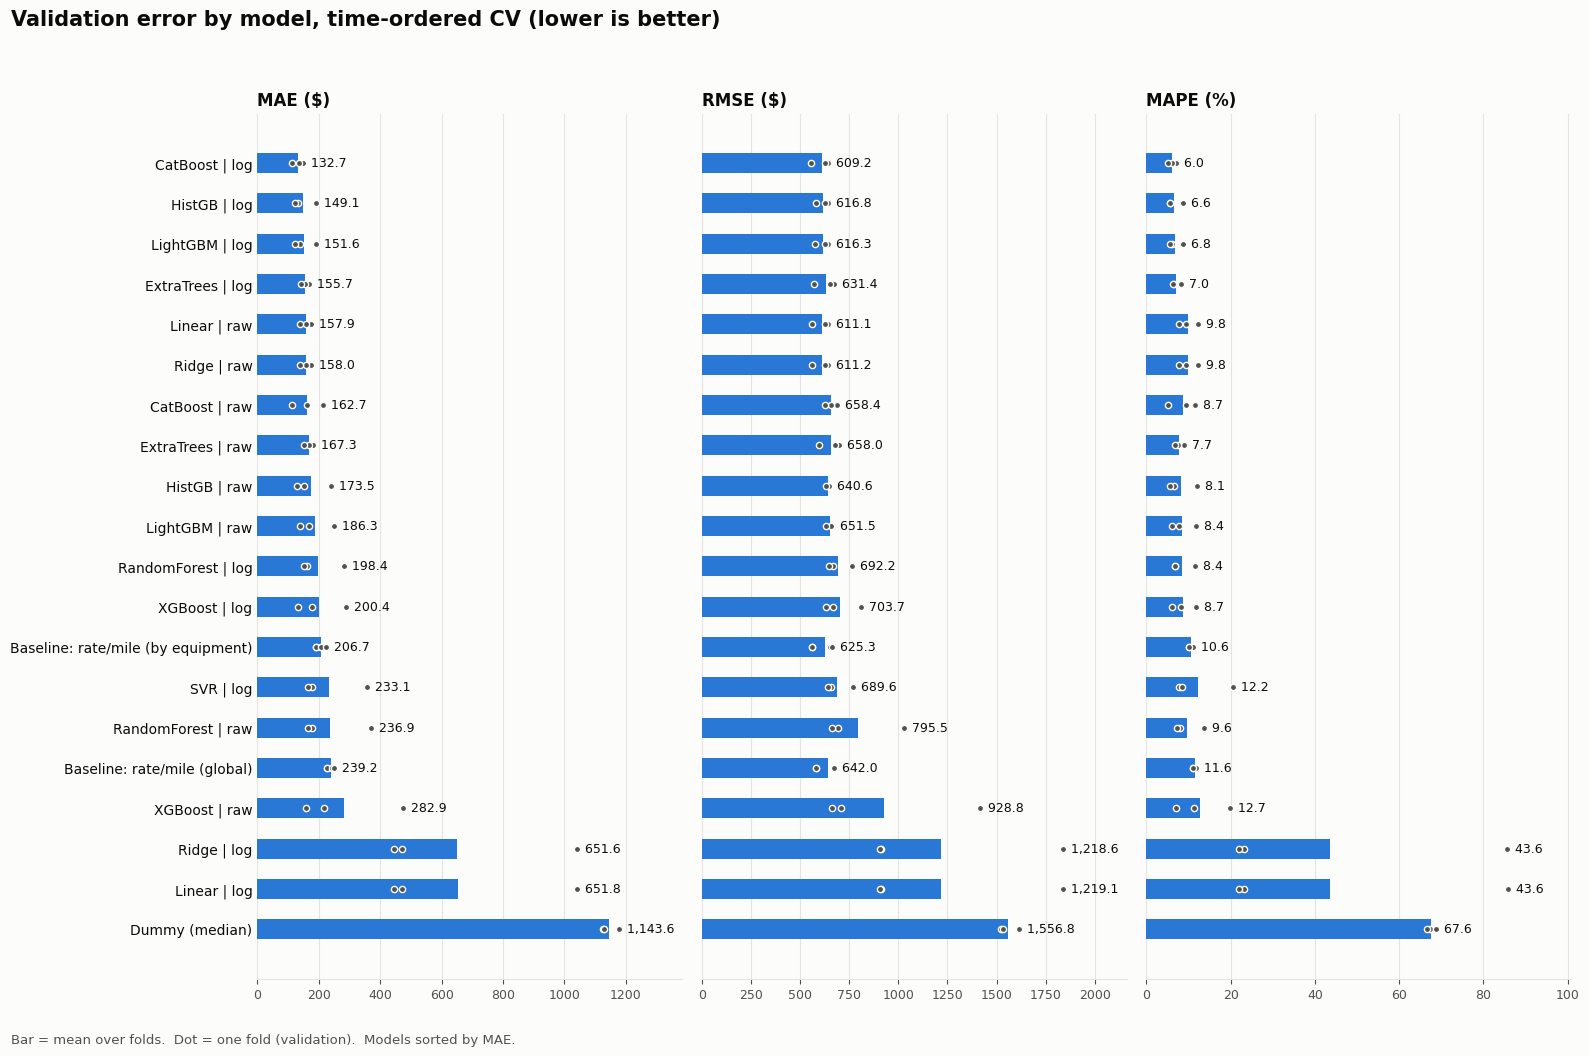

In [30]:
# Plot the validation errors of all models
SURFACE, INK, INK_2, GRID, BAR, DOT = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0", "#2a78d6", "#52514e"
metrics = {"val_mae": "MAE ($)", "val_rmse": "RMSE ($)", "val_mape": "MAPE (%)"}

mean = bench.groupby("model")[list(metrics)].mean().sort_values("val_mae")
order = list(mean.index[::-1])

fig, axes = plt.subplots(1, 3, figsize=(16, 0.42 * len(order) + 2.2), sharey=True, facecolor=SURFACE)
for ax, (col, title) in zip(axes, metrics.items()):
    k = 100 if col == "val_mape" else 1
    ax.set_facecolor(SURFACE)
    for y, m in enumerate(order):
        pts = bench.loc[bench["model"] == m, col] * k
        bar = mean.loc[m, col] * k
        ax.barh(y, bar, height=0.5, color=BAR)
        ax.scatter(pts, [y] * len(pts), s=20, color=DOT, edgecolor=SURFACE, linewidth=1, zorder=3)
        ax.text(max(bar, pts.max()), y, f"  {bar:,.1f}", va="center", ha="left", fontsize=9, color=INK)
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", color=INK)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=10, color=INK)
    ax.tick_params(axis="x", colors=INK_2, labelsize=9)
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, ax.get_xlim()[1] * 1.12)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

fig.suptitle("Validation error by model, time-ordered CV (lower is better)",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.005, "Bar = mean over folds.  Dot = one fold (validation).  Models sorted by MAE.",
         fontsize=9.5, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig("model_comparison.png", dpi=180, bbox_inches="tight", facecolor=SURFACE)
plt.show()


## Error analysis

Out-of-fold predictions of a HistGB model on the dev part, to see where the errors come from.

In [31]:
# Out-of-fold predictions of HistGB, to analyse the errors
hgb = build(HistGradientBoostingRegressor(random_state=SEED), log_target=True)

parts = []
for i, (tr, va) in enumerate(splits):
    est = clone(hgb)
    est.fit(X_dev.iloc[tr], y_dev.iloc[tr])
    part = X_dev.iloc[va].copy()
    part["fold"] = i
    part["y"] = y_dev.iloc[va].to_numpy()
    part["pred"] = est.predict(X_dev.iloc[va])
    parts.append(part)

resid = pd.concat(parts)
resid["err"] = resid["y"] - resid["pred"]            # > 0: model underestimates
resid["abs_err"] = resid["err"].abs()
resid["pct_err"] = resid["abs_err"] / resid["y"]
resid["rpm"] = resid["y"] / resid["distance"]        # actual rate per mile
resid["month"] = resid["date"].dt.to_period("M")
resid["weight"] = resid["weight"].abs()              # raw weight still has negative signs here

print(resid.shape)
resid[["y", "pred", "err", "abs_err", "pct_err"]].describe().round(2)


(29222, 21)


,y,pred,err,abs_err,pct_err
count,29222.00,29222.00,29222.00,29222.00,29222.00
mean,2402.69,2344.30,58.39,149.38,0.07
std,1500.88,1383.12,614.40,598.82,0.24
min,59.68,199.56,-4722.75,0.00,0.00
25%,1274.81,1242.08,-16.34,24.73,0.01
50%,2054.25,2016.92,30.51,59.38,0.03
75%,3388.98,3332.79,92.63,128.05,0.06
max,25533.00,7394.05,20456.32,20456.32,5.75


In [32]:
# How concentrated the errors are
s = resid["abs_err"].sort_values(ascending=False)
sq = (resid["err"] ** 2).sort_values(ascending=False)
for q in (0.01, 0.05, 0.10):
    n = int(len(resid) * q)
    print(f"top {q:>4.0%} rows ({n:>5}) -> {s.iloc[:n].sum() / s.sum():5.1%} of total abs error"
          f" | {sq.iloc[:n].sum() / sq.sum():5.1%} of total squared error (RMSE)")
print()
print(resid["abs_err"].describe(percentiles=[.5, .9, .99]).round(1))

top   1% rows (  292) -> 31.9% of total abs error | 92.1% of total squared error (RMSE)
top   5% rows ( 1461) -> 48.7% of total abs error | 96.9% of total squared error (RMSE)
top  10% rows ( 2922) -> 58.7% of total abs error | 98.1% of total squared error (RMSE)

count    29222.0
mean       149.4
std        598.8
min          0.0
50%         59.4
90%        246.3
99%       1376.0
max      20456.3
Name: abs_err, dtype: float64


In [33]:
# Errors by segment
resid["dist_bin"]   = pd.cut(resid["distance"], [0, 150, 300, 600, 1000, 1500, 2000, 2500, 4000])
resid["weight_bin"] = pd.cut(resid["weight"], [0, 10000, 20000, 30000, 40000, 47499, 47500])
resid["mkt_bin"]    = pd.qcut(resid["market_index"], 5)
resid["rpm_bin"]    = pd.cut(resid["rpm"], [0, 1, 1.5, 2, 2.5, 3, 4, 20])


def by(col):
    g = resid.groupby(col, observed=True)
    return pd.DataFrame({
        "n": g.size(),
        "MAE": g["abs_err"].mean(),
        "MAPE_%": g["pct_err"].mean() * 100,
        "bias": g["err"].mean(),            # signed: > 0 = underestimate
    }).round(1)


for col in ["dist_bin", "equipment", "month", "fold", "weight_bin", "mkt_bin", "rpm_bin"]:
    print(f"\n--- by {col}")
    display(by(col))



--- by dist_bin


,n,MAE,MAPE_%,bias
dist_bin,,,,
"(0, 150]",513,40.8,12.2,25.8
"(150, 300]",1932,48.5,7.8,27.3
"(300, 600]",5686,70.7,6.6,47.8
"(600, 1000]",7285,115.4,6.8,65.3
"(1000, 1500]",5488,158.1,5.7,85.1
"(1500, 2000]",3770,212.1,5.9,89.4
"(2000, 2500]",2936,247.5,6.1,42.3
"(2500, 4000]",1612,380.9,8.0,-22.2



--- by equipment


,n,MAE,MAPE_%,bias
equipment,,,,
Dry Van,16561,136.2,6.1,24.8
Flatbed,5310,150.8,6.4,76.4
Reefer,7351,178.0,8.0,120.9



--- by month


...

,n,MAE,MAPE_%,bias
weight_bin,,,,
"(0, 10000]",121,177.4,8.7,28.2
"(10000, 20000]",2170,147.1,6.7,53.1
"(20000, 30000]",10215,148.1,6.7,52.6
"(30000, 40000]",12270,146.0,6.3,57.8
"(40000, 47499]",3562,162.2,6.8,82.3
"(47499, 47500]",716,170.1,7.2,65.0



--- by mkt_bin


,n,MAE,MAPE_%,bias
mkt_bin,,,,
"(0.762, 1.034]",5799,127.5,6.1,61.0
"(1.034, 1.148]",5798,156.8,6.9,30.6
"(1.148, 1.224]",5799,157.2,7.0,50.8
"(1.224, 1.317]",5799,148.7,6.2,74.6
"(1.317, 1.468]",5798,157.1,6.8,74.7



--- by rpm_bin


,n,MAE,MAPE_%,bias
rpm_bin,,,,
"(0.0, 1.0]",193,1640.8,274.6,-1640.8
"(1.0, 1.5]",5,768.5,142.3,-768.5
"(1.5, 2.0]",6413,153.7,4.2,-61.4
"(2.0, 2.5]",18324,92.1,4.0,60.2
"(2.5, 3.0]",3792,56.3,5.9,42.3
"(3.0, 4.0]",298,40.2,8.4,36.9
"(4.0, 20.0]",197,5815.6,71.0,5815.6


In [34]:
# The 20 largest errors
cols = ["load_id", "pickup", "delivery", "distance", "equipment", "weight",
        "date", "market_index", "quote_signal", "y", "pred", "err", "rpm"]
resid.sort_values("abs_err", ascending=False)[cols].head(20).round(2)

,load_id,pickup,delivery,distance,equipment,weight,date,market_index,quote_signal,y,pred,err,rpm
12246,TR-012185,Bakersfield,Hartford,2829.8,Dry Van,33153.0,2025-03-19,1.17,1.83,25533.00,5076.68,20456.32,9.02
37833,TR-037765,Phoenix,Syracuse,2810.9,Dry Van,33674.0,2025-08-27,1.05,2.16,24294.98,5223.01,19071.97,8.64
26298,TR-026236,Charleston,Phoenix,2552.5,Dry Van,25665.0,2025-06-15,1.20,1.81,23580.42,4518.34,19062.08,9.24
28277,TR-028220,Tucson,Raleigh,2423.3,Dry Van,30972.0,2025-06-27,1.33,1.97,22755.66,4672.00,18083.66,9.39
17459,TR-017372,Reno,Philadelphia,2777.6,Reefer,33158.0,2025-04-20,1.15,2.16,23662.71,6247.19,17415.52,8.52
31335,TR-031260,Oklahoma City,Baltimore,1747.7,Reefer,28876.0,2025-07-16,1.34,1.80,19042.39,3835.37,15207.02,10.90
34656,TR-034584,Atlanta,Fresno,2242.0,Dry Van,32005.0,2025-08-06,1.10,1.99,18972.15,4307.03,14665.12,8.46
32979,TR-033075,Mobile,Phoenix,1880.0,Reefer,21494.0,2025-07-27,0.97,2.04,17333.65,3813.60,13520.05,9.22
35408,TR-035469,Lexington,Fresno,2305.9,Dry Van,42707.0,2025-08-12,0.95,2.29,17742.34,4224.85,13517.49,7.69
20341,TR-020246,Atlanta,Los Angeles,2153.5,Reefer,31758.0,2025-05-08,1.43,1.96,17772.53,4490.38,13282.15,8.25


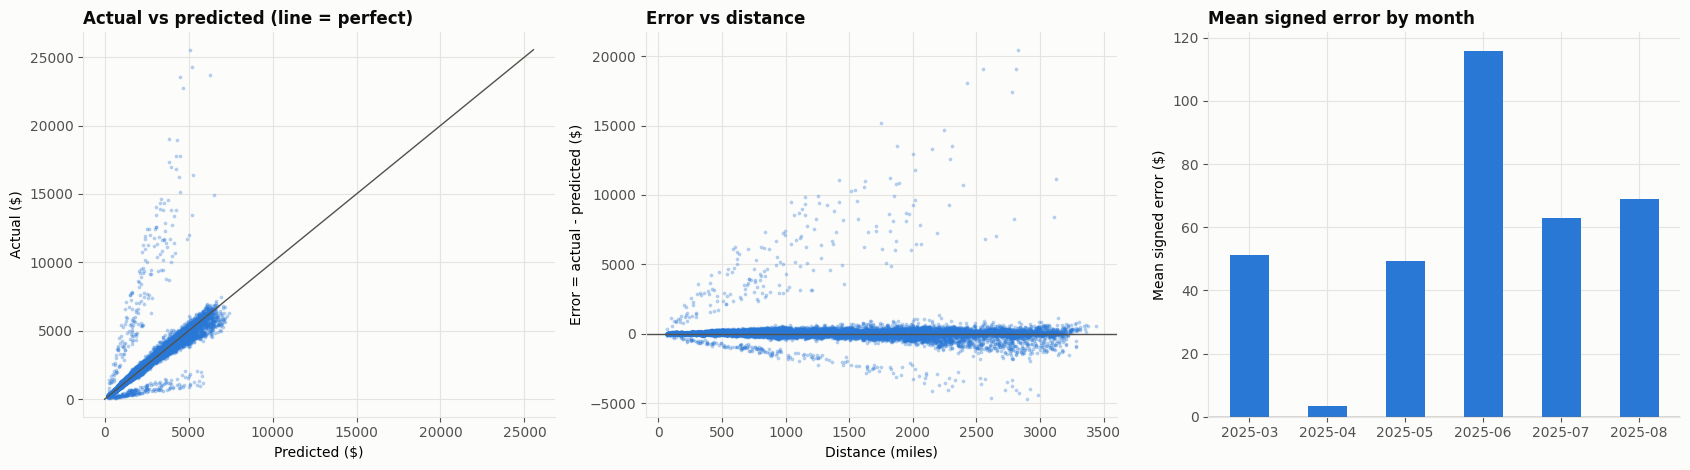

In [35]:
# Plots: actual vs predicted, error vs distance, bias by month
SURFACE, INK, INK_2, GRID, BAR = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0", "#2a78d6"

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), facecolor=SURFACE)

lim = [0, float(resid[["y", "pred"]].max().max())]
axes[0].scatter(resid["pred"], resid["y"], s=3, alpha=0.25, color=BAR)
axes[0].plot(lim, lim, color=INK_2, linewidth=1)
axes[0].set_xlabel("Predicted ($)")
axes[0].set_ylabel("Actual ($)")
axes[0].set_title("Actual vs predicted (line = perfect)", loc="left", fontweight="bold", color=INK)

axes[1].scatter(resid["distance"], resid["err"], s=3, alpha=0.25, color=BAR)
axes[1].axhline(0, color=INK_2, linewidth=1)
axes[1].set_xlabel("Distance (miles)")
axes[1].set_ylabel("Error = actual - predicted ($)")
axes[1].set_title("Error vs distance", loc="left", fontweight="bold", color=INK)

m = resid.groupby("month", observed=True)["err"].mean()
axes[2].bar(m.index.astype(str), m.values, width=0.5, color=BAR)
axes[2].axhline(0, color=INK_2, linewidth=1)
axes[2].set_ylabel("Mean signed error ($)")
axes[2].set_title("Mean signed error by month", loc="left", fontweight="bold", color=INK)

for ax in axes:
    ax.set_facecolor(SURFACE)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=INK_2)

fig.tight_layout()
plt.show()


## Price outliers

Are the rows with an abnormal price predictable?

outliers: 533 rows = 1.39% of dev
too high (> 4 $/mile): 267 | too low (< 1.5 $/mile): 266

outlier rate (%) by dow   (overall = 1.39%)


dow,0,1,2,3,4,5,6
outlier_%,1.41,1.53,1.41,1.52,1.35,1.22,1.26



outlier rate (%) by week_of_month   (overall = 1.39%)


week_of_month,1,2,3,4,5
outlier_%,1.33,1.36,1.4,1.34,1.72



outlier rate (%) by month   (overall = 1.39%)


month,1,2,3,4,5,6,7,8
outlier_%,1.65,1.31,1.41,1.37,1.26,1.32,1.32,1.43


outliers per day: mean 2.19 | variance 2.02 | variance/mean 0.92 (about 1 = random)
lag-1 autocorrelation of the outlier flag: -0.0026 (0 = no clustering)
fold 0: AUC = 0.498   (0.5 = chance)
fold 1: AUC = 0.508   (0.5 = chance)
fold 2: AUC = 0.503   (0.5 = chance)


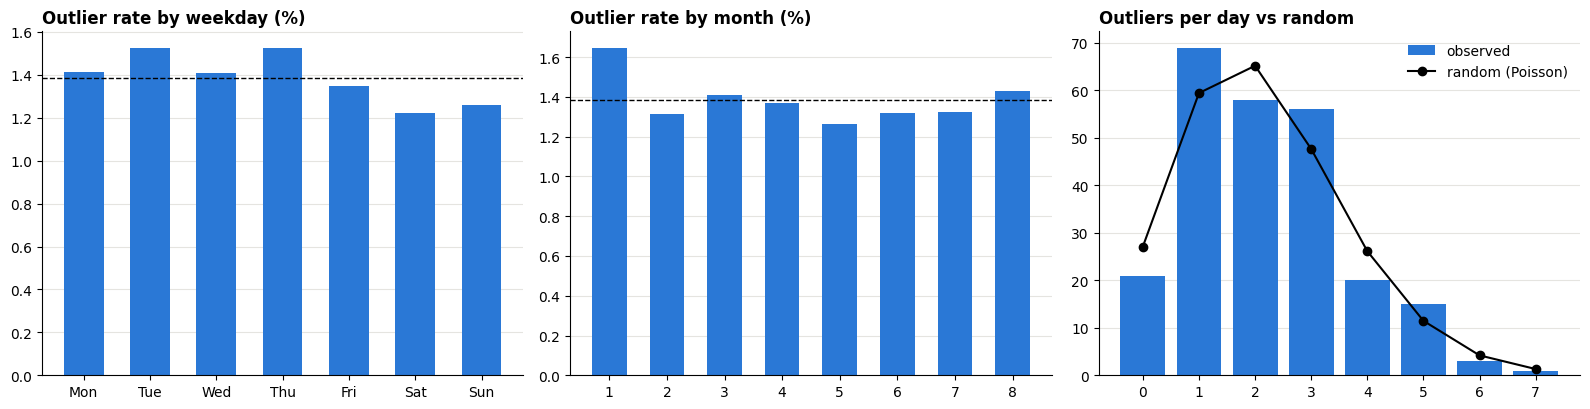

In [36]:
# Price outliers: define them (rate per mile above 4 or below 1.5) and add calendar columns
eda = X_dev.copy()
eda["y"] = y_dev.to_numpy()
eda["rpm"] = eda["y"] / eda["distance"]               
eda["weight"] = eda["weight"].abs()
eda["is_out"] = (eda["rpm"] > 4) | (eda["rpm"] < 1.5)   

eda["dow"] = eda["date"].dt.dayofweek
eda["dom"] = eda["date"].dt.day
eda["week_of_month"] = (eda["dom"] - 1) // 7 + 1
eda["month"] = eda["date"].dt.month
eda["pos_in_day"] = eda.groupby("date").cumcount()

base = eda["is_out"].mean()
print(f"outliers: {eda['is_out'].sum()} rows = {base:.2%} of dev")
print("too high (> 4 $/mile):", int((eda["rpm"] > 4).sum()), "| too low (< 1.5 $/mile):", int((eda["rpm"] < 1.5).sum()))

# Outlier rate by weekday, week of the month and month
for col in ["dow", "week_of_month", "month"]:
    print(f"\noutlier rate (%) by {col}   (overall = {base * 100:.2f}%)")
    display((eda.groupby(col)["is_out"].mean() * 100).round(2).to_frame("outlier_%").T)

# Are outliers clustered in time? Compare with random counts
daily = eda.groupby("date")["is_out"].sum()
print("outliers per day: mean", round(daily.mean(), 2), "| variance", round(daily.var(), 2),
      "| variance/mean", round(daily.var() / daily.mean(), 2), "(about 1 = random)")

flag = eda["is_out"].astype(float).to_numpy()
print("lag-1 autocorrelation of the outlier flag:", round(np.corrcoef(flag[:-1], flag[1:])[0, 1], 4), "(0 = no clustering)")

# Can one feature alone predict an outlier? (AUC)
from sklearn.metrics import roc_auc_score

feats = ["distance", "weight", "market_index", "quote_signal", "dow", "dom", "month", "pos_in_day"]
tmp = eda[feats].fillna(eda[feats].median())
auc = {f: roc_auc_score(eda["is_out"], tmp[f]) for f in feats}
pd.Series({f: max(a, 1 - a) for f, a in auc.items()}, name="AUC (0.5 = no signal)").round(3).sort_values(ascending=False)

# Can all features together predict an outlier? (classifier, time-ordered CV)
from sklearn.ensemble import HistGradientBoostingClassifier

Xc = eda[["distance", "weight", "market_index", "quote_signal", "dow", "dom", "month",
          "pos_in_day", "equipment", "pickup", "delivery"]].copy()
for c in ["equipment", "pickup", "delivery"]:
    Xc[c] = Xc[c].astype("category")
yc = eda["is_out"]

for i, (tr, va) in enumerate(splits):
    clf = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=SEED)
    clf.fit(Xc.iloc[tr], yc.iloc[tr])
    p = clf.predict_proba(Xc.iloc[va])[:, 1]
    print(f"fold {i}: AUC = {roc_auc_score(yc.iloc[va], p):.3f}   (0.5 = chance)")

# Plots: outlier rate by weekday and month, outliers per day vs random
import math

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

dow_rate = eda.groupby("dow")["is_out"].mean() * 100
axes[0].bar(range(7), dow_rate.values, color="#2a78d6", width=0.6)
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[0].axhline(base * 100, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Outlier rate by weekday (%)", loc="left", fontweight="bold")

month_rate = eda.groupby("month")["is_out"].mean() * 100
axes[1].bar(month_rate.index, month_rate.values, color="#2a78d6", width=0.6)
axes[1].axhline(base * 100, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Outlier rate by month (%)", loc="left", fontweight="bold")

lam = daily.mean()
ks = np.arange(0, int(daily.max()) + 1)
pmf = np.array([math.exp(-lam) * lam ** k / math.factorial(k) for k in ks])
axes[2].hist(daily, bins=np.arange(0, daily.max() + 2) - 0.5, color="#2a78d6", rwidth=0.8, label="observed")
axes[2].plot(ks, pmf * len(daily), "o-", color="black", label="random (Poisson)")
axes[2].set_title("Outliers per day vs random", loc="left", fontweight="bold")
axes[2].legend(frameon=False)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()


## Conclusion: random price outliers, and why MAE is the main metric

**What I found**
- About 1.4% of rows (533 of the dev data) have a price that is far from normal: 267 are too high (more than 4 USD per mile) and 266 are too low (less than 1.5 USD per mile). Normal rows sit around 1.7 to 3.0 USD per mile.
- These few rows dominate the RMSE: the worst 1% of validation rows produce about 92% of the total squared error, but only about 32% of the total absolute error.
- I looked for a pattern and found none:
  - the outlier rate is flat by weekday, week of the month and month (about 1.2 to 1.7%, overall 1.39%);
  - outliers per day behave like random counts (variance/mean = 0.92) and are not clustered (lag-1 autocorrelation = -0.003);
  - a classifier trained to detect outlier rows from all features (distance, weight, market index, quote signal, equipment, cities, calendar) is at chance level in time-ordered CV (AUC 0.498, 0.508, 0.503).

**Conclusion**
These rows behave like random noise in the target. With the features available, there is no way to predict them, so feature engineering cannot recover them.

**Decisions**
1. I keep these rows in the data and I do not delete them.
2. **MAE is the main metric from now on, not RMSE.**

**Why MAE**
- RMSE squares errors, so it mostly measures this unpredictable noise (about 1% of rows) and hardly separates a good model from a bad one on normal loads.
- MAE is in dollars, easy to explain, and gives the typical size of the error without being dominated by a few rows.
- MAPE is also inflated by the too-low prices (small denominator), so I read it with care and I look at the median percentage error.
- I still report RMSE and MAPE for reference, but I do not select models with them.

**Limit**
I only checked the available columns. I cannot rule out a cause outside the data provided, and the final scoring metric is computed by the evaluator, so I report several metrics.

In [37]:
# Helpers: preprocessing, targets, models and the CV runner
import math
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

BASE_NUM = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
            "distance", "weight", "market_index", "quote_signal"]
BASE_CAT = ["equipment"]


# Stateless feature creation, applied after the imputation
def add_feats(df, which=()):
    df = df.copy()
    if "dow" in which:
        df["dow"] = df["date"].dt.dayofweek
    if "interact" in which:
        df["dist_x_market"] = df["distance"] * df["market_index"]
        df["dist_x_quote"] = df["distance"] * df["quote_signal"]
    if "direction" in which:
        df["d_lat"] = df["delivery_lat"] - df["pickup_lat"]
        df["d_lon"] = df["delivery_lon"] - df["pickup_lon"]
    return df


NEW_COLS = {"dow": ["dow"],
            "interact": ["dist_x_market", "dist_x_quote"],
            "direction": ["d_lat", "d_lon"]}


def make_prep(drop_num=(), drop_cat=(), which=()):
    num = [c for c in BASE_NUM if c not in drop_num] + [c for w in which for c in NEW_COLS[w]]
    cat = [c for c in BASE_CAT if c not in drop_cat]
    enc = ColumnTransformer(
        [("num", "passthrough", num),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)],
        remainder="drop", verbose_feature_names_out=False)
    enc.set_output(transform="pandas")
    return Pipeline([
        ("clean", FunctionTransformer(cleaning)),
        ("impute", MyStatefulTransformer()),
        ("feats", FunctionTransformer(add_feats, kw_args={"which": tuple(which)})),
        ("encode", enc),
    ])


# Optional target: train on the rate per mile, predict price = rate x distance
class RpmTarget(BaseEstimator, RegressorMixin):
    def __init__(self, regressor):
        self.regressor = regressor

    def fit(self, X, y):
        self.regressor_ = clone(self.regressor)
        self.regressor_.fit(X, y / X["distance"])
        return self

    def predict(self, X):
        return self.regressor_.predict(X) * X["distance"].to_numpy()


def make_model(kind, loss="squared"):
    if kind == "HistGB":
        return HistGradientBoostingRegressor(
            loss="absolute_error" if loss == "l1" else "squared_error", random_state=SEED)
    if kind == "LightGBM":
        return LGBMRegressor(objective="l1" if loss == "l1" else "regression",
                             n_estimators=400, learning_rate=0.05, random_state=SEED, verbose=-1)
    if kind == "ExtraTrees":
        return ExtraTreesRegressor(n_estimators=200, n_jobs=-1, random_state=SEED)


def make_est(kind, prep, target="log", loss="squared"):
    est = Pipeline([("prep", prep), ("model", make_model(kind, loss))])
    if target == "log":
        return TransformedTargetRegressor(regressor=est, func=np.log1p, inverse_func=np.expm1)
    if target == "rpm":
        return RpmTarget(est)
    return est


TOP3 = ["HistGB", "LightGBM", "ExtraTrees"]
results = []


def run(step, variant, kind, est):
    maes, mapes, rmses, medapes = [], [], [], []
    for tr, va in splits:
        m = clone(est).fit(X_dev.iloc[tr], y_dev.iloc[tr])
        p = m.predict(X_dev.iloc[va])
        yv = y_dev.iloc[va].to_numpy()
        maes.append(mean_absolute_error(yv, p))
        rmses.append(np.sqrt(mean_squared_error(yv, p)))
        ape = np.abs(yv - p) / yv
        mapes.append(ape.mean())
        medapes.append(np.median(ape))
    results.append({"step": step, "variant": variant, "model": kind,
                    "mae": np.mean(maes), "mae_std": np.std(maes), "mae_folds": maes,
                    "medape_%": np.mean(medapes) * 100, "mape_%": np.mean(mapes) * 100,
                    "rmse": np.mean(rmses)})


def show(step, ref):
    d = pd.DataFrame([r for r in results if r["step"] == step])
    order = list(pd.unique(d["variant"]))
    mae = d.pivot(index="variant", columns="model", values="mae").loc[order]
    delta = mae - mae.loc[ref]
    wins = pd.DataFrame(index=order, columns=mae.columns, dtype=float)
    for m in mae.columns:
        ref_row = d[(d.variant == ref) & (d.model == m)]
        for v in order:
            row = d[(d.variant == v) & (d.model == m)]
            if len(row) and len(ref_row):
                wins.loc[v, m] = (np.array(row["mae_folds"].iloc[0]) < np.array(ref_row["mae_folds"].iloc[0])).sum()
    print("MAE ($), mean over folds");                                   display(mae.round(1))
    print(f"Delta MAE vs '{ref}' (negative = better)");                  display(delta.round(1))
    print(f"Folds (out of {len(splits)}) where the variant beats the reference"); display(wins.astype("Int64"))
    return delta


def plot_delta(delta, title):
    SURFACE, INK, INK_2, GRID, BAR = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0", "#2a78d6"
    n = len(delta)
    fig, axes = plt.subplots(1, len(delta.columns), figsize=(5.4 * len(delta.columns), 0.55 * n + 1.8),
                             sharey=True, facecolor=SURFACE)
    axes = np.atleast_1d(axes)
    for ax, m in zip(axes, delta.columns):
        vals = delta[m].to_numpy(dtype=float)
        ax.set_facecolor(SURFACE)
        ax.barh(range(n), np.nan_to_num(vals), height=0.5, color=BAR)
        for y, v in enumerate(vals):
            ax.text(0 if np.isnan(v) else v, y, " n/a" if np.isnan(v) else f" {v:+.1f}",
                    va="center", ha="left" if np.isnan(v) or v >= 0 else "right", fontsize=9, color=INK)
        ax.axvline(0, color=INK_2, linewidth=1)
        ax.set_yticks(range(n))
        ax.set_yticklabels(delta.index, fontsize=10, color=INK)
        ax.invert_yaxis()
        ax.set_title(m, loc="left", fontweight="bold", color=INK)
        ax.set_xlabel("Change in MAE ($)  (left = better)", color=INK_2)
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.spines["bottom"].set_color(GRID)
        ax.tick_params(axis="y", length=0)
        lo, hi = np.nanmin(vals), np.nanmax(vals)
        pad = 0.25 * max(hi - lo, 1.0)
        ax.set_xlim(min(lo, 0) - pad, max(hi, 0) + pad)
    fig.suptitle(title, x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()


HistGB done
LightGBM done
ExtraTrees done
MAE ($), mean over folds


model,ExtraTrees,HistGB,LightGBM
variant,,,
all features,155.7,149.1,151.6
- coords (4),162.5,154.2,165.3
- weight,164.1,164.1,173.5
- market_index,163.3,158.5,164.1
- quote_signal,158.1,132.9,140.3
- equipment,195.4,180.4,188.9
- distance,376.9,447.6,399.5


Delta MAE vs 'all features' (negative = better)


model,ExtraTrees,HistGB,LightGBM
variant,,,
all features,0.0,0.0,0.0
- coords (4),6.8,5.1,13.7
- weight,8.4,14.9,21.9
- market_index,7.6,9.4,12.6
- quote_signal,2.4,-16.3,-11.2
- equipment,39.7,31.3,37.3
- distance,221.2,298.5,247.9


Folds (out of 3) where the variant beats the reference


model,ExtraTrees,HistGB,LightGBM
all features,0,0,0
- coords (4),1,0,0
- weight,0,0,0
- market_index,1,1,0
- quote_signal,2,2,2
- equipment,0,0,0
- distance,0,0,0


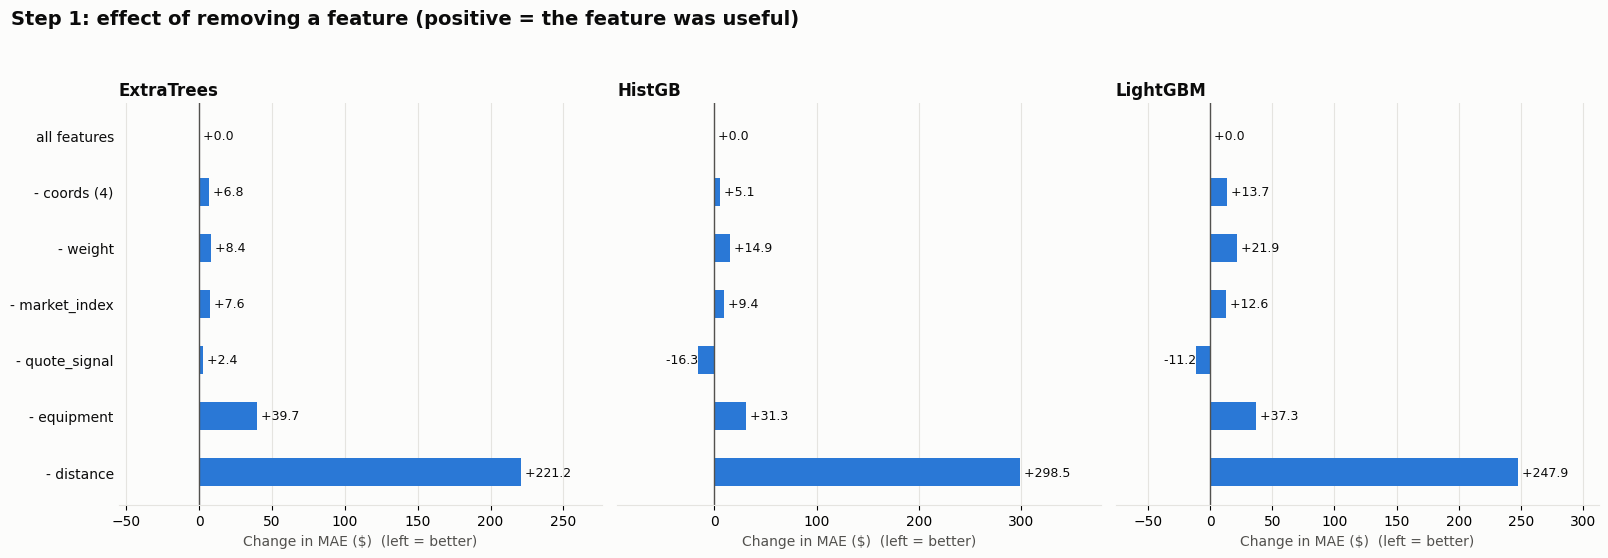

In [38]:
# Effect of removing each feature, time-ordered CV
ablation = {
    "all features":   dict(),
    "- coords (4)":   dict(drop_num=["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]),
    "- weight":       dict(drop_num=["weight"]),
    "- market_index": dict(drop_num=["market_index"]),
    "- quote_signal": dict(drop_num=["quote_signal"]),
    "- equipment":    dict(drop_cat=["equipment"]),
    "- distance":     dict(drop_num=["distance"]),
}

for kind in TOP3:
    for variant, kw in ablation.items():
        run("1-ablation", variant, kind, make_est(kind, make_prep(**kw)))
    print(kind, "done")

delta1 = show("1-ablation", "all features")
plot_delta(delta1, "Step 1: effect of removing a feature (positive = the feature was useful)")

In [39]:
# Permutation importance: increase in MAE when a column is shuffled
def permutation_mae(est, Xva, yva, cols, n_repeats=5, seed=SEED):
    rng = np.random.default_rng(seed)
    base = mean_absolute_error(yva, est.predict(Xva))
    out = {}
    for c in cols:
        deltas = []
        for _ in range(n_repeats):
            Xp = Xva.copy()
            Xp[c] = rng.permutation(Xp[c].to_numpy())
            deltas.append(mean_absolute_error(yva, est.predict(Xp)) - base)
        out[c] = np.mean(deltas)
    return out


est1 = make_est("HistGB", make_prep())
imp = []
for tr, va in splits:
    m = clone(est1).fit(X_dev.iloc[tr], y_dev.iloc[tr])
    imp.append(permutation_mae(m, X_dev.iloc[va], y_dev.iloc[va], BASE_NUM + BASE_CAT))
imp = pd.DataFrame(imp, index=[f"fold {i}" for i in range(len(splits))]).T
imp["mean"] = imp.mean(axis=1)
print("Increase in MAE ($) when the column is shuffled (HistGB, log target)")
imp.sort_values("mean", ascending=False).round(1)



Increase in MAE ($) when the column is shuffled (HistGB, log target)


,fold 0,fold 1,fold 2,mean
distance,1392.0,1449.1,1408.6,1416.5
equipment,12.5,66.3,64.5,47.7
quote_signal,38.0,21.5,11.6,23.7
weight,4.6,18.4,19.1,14.0
market_index,-1.0,3.6,21.8,8.1
delivery_lat,2.8,1.2,4.6,2.9
pickup_lat,-1.8,2.5,4.6,1.7
delivery_lon,-2.5,2.4,0.8,0.2
pickup_lon,-3.1,0.5,1.1,-0.5


## Is quote_signal stable over time? (decision: keep or drop it)

Dev months only for anything that uses prices. validation.csv is used only through its features (no labels exist).

Global correlation, quote_signal vs price         : -0.054
Global correlation, quote_signal vs rate per mile : 0.116
Correlation with the rate per mile, month by month


month,1,2,3,4,5,6,7,8
quote_signal,0.995,0.995,0.996,-0.991,-0.992,0.996,-0.992,-0.023
market_index,0.086,0.109,0.116,0.146,0.085,0.051,0.152,0.085


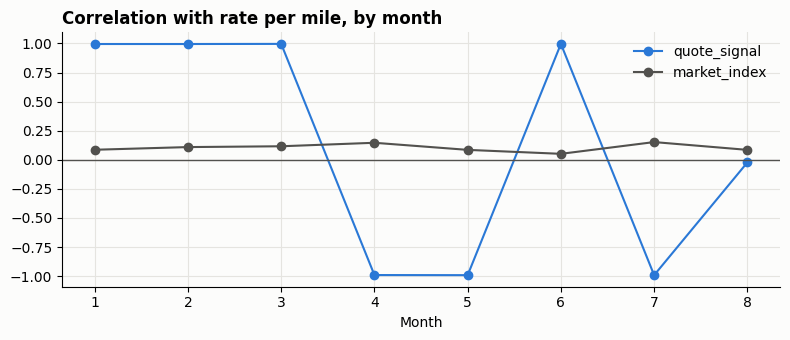

In [40]:
# quote_signal vs rate per mile, month by month
# Dev months only, normal rows only (price outliers removed)
norm = eda[~eda["is_out"]]

print("Global correlation, quote_signal vs price         :", round(eda["quote_signal"].corr(eda["y"]), 3))
print("Global correlation, quote_signal vs rate per mile :", round(norm["quote_signal"].corr(norm["rpm"], method="spearman"), 3))


def by_month(col):
    return norm.groupby("month").apply(
        lambda g: g[col].corr(g["rpm"], method="spearman"), include_groups=False)


corr_month = pd.DataFrame({"quote_signal": by_month("quote_signal"),
                           "market_index": by_month("market_index")}).round(3)
print("Correlation with the rate per mile, month by month")
display(corr_month.T)

fig, ax = plt.subplots(figsize=(8, 3.5), facecolor="#fcfcfb")
ax.plot(corr_month.index, corr_month["quote_signal"], "o-", color="#2a78d6", label="quote_signal")
ax.plot(corr_month.index, corr_month["market_index"], "o-", color="#52514e", label="market_index")
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_title("Correlation with rate per mile, by month", loc="left", fontweight="bold")
ax.set_xlabel("Month")
ax.legend(frameon=False)
ax.set_facecolor("#fcfcfb")
ax.grid(color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


std of the daily means: 0.159 | average std inside one day: 0.025
daily market_index vs daily mean rate per mile (Spearman): 0.855
market_index vs rate per mile, month by month


month,1,2,3,4,5,6,7,8
corr_with_rpm,0.086,0.109,0.116,0.146,0.085,0.051,0.152,0.085
corr_after_equipment,0.097,0.117,0.142,0.153,0.113,0.071,0.160,0.118
slope_rpm_per_unit,0.273,0.296,0.376,0.349,0.266,0.189,0.333,0.251


market_index mean / std by month (dev, then validation)


date,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-11,2025-12
mean,0.927,0.996,1.073,1.208,1.301,1.280,1.201,0.981,0.919,0.935
std,0.078,0.083,0.080,0.100,0.074,0.076,0.116,0.078,0.074,0.073


dev range: 0.73 to 1.47 | validation range: 0.72 to 1.10


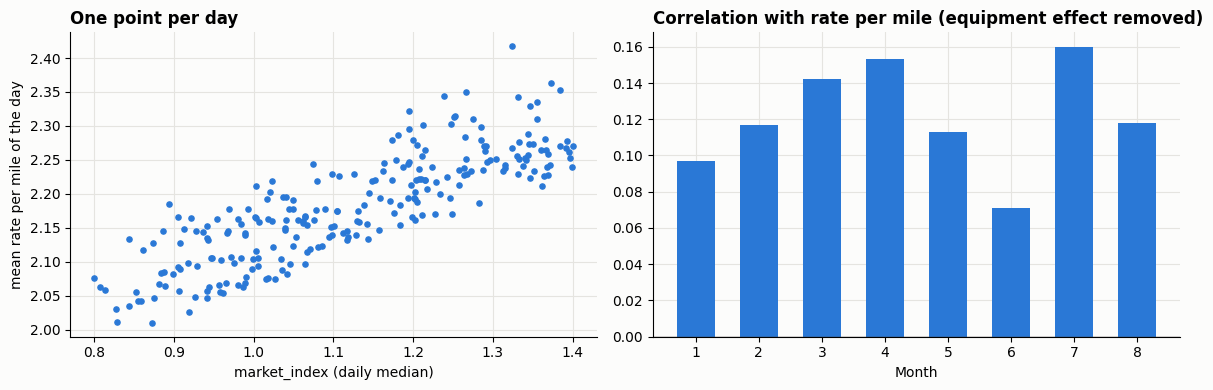

In [41]:
# market_index: daily level, link with the price, stability by month, validation range
# Dev months only, normal rows only (price outliers removed)
norm = eda[~eda["is_out"]].copy()
norm["rpm_vs_equipment"] = norm["rpm"] - norm.groupby("equipment")["rpm"].transform("mean")   # remove the equipment effect

# Daily level of market_index
g = eda.groupby("date")["market_index"]
print(f"std of the daily means: {g.mean().std():.3f} | average std inside one day: {g.std().mean():.3f}")

# Does the daily level follow the daily rate per mile?
day = norm.groupby("date").agg(mi=("market_index", "median"), rpm=("rpm", "mean"))
print("daily market_index vs daily mean rate per mile (Spearman):", round(day["mi"].corr(day["rpm"], method="spearman"), 3))


# Is the relationship stable from month to month?
def month_stats(d):
    d = d.dropna(subset=["market_index"])
    return pd.Series({"corr_with_rpm": d["market_index"].corr(d["rpm"], method="spearman"),
                      "corr_after_equipment": d["market_index"].corr(d["rpm_vs_equipment"], method="spearman"),
                      "slope_rpm_per_unit": np.polyfit(d["market_index"], d["rpm"], 1)[0]})


stab = norm.groupby("month").apply(month_stats, include_groups=False).round(3)
print("market_index vs rate per mile, month by month")
display(stab.T)

# Are the validation months inside the dev range?
dev_m = X_dev.groupby(X_dev["date"].dt.strftime("%Y-%m"))["market_index"].agg(["mean", "std"])
val_m = val_df.groupby(val_df["date"].astype(str).str[:7])["market_index"].agg(["mean", "std"])
print("market_index mean / std by month (dev, then validation)")
display(pd.concat([dev_m, val_m]).round(3).T)
print(f"dev range: {X_dev['market_index'].min():.2f} to {X_dev['market_index'].max():.2f} | "
      f"validation range: {val_df['market_index'].min():.2f} to {val_df['market_index'].max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor="#fcfcfb")
axes[0].scatter(day["mi"], day["rpm"], s=14, color="#2a78d6")
axes[0].set_xlabel("market_index (daily median)")
axes[0].set_ylabel("mean rate per mile of the day")
axes[0].set_title("One point per day", loc="left", fontweight="bold")
axes[1].bar(stab.index, stab["corr_after_equipment"], color="#2a78d6", width=0.6)
axes[1].axhline(0, color="#52514e", linewidth=1)
axes[1].set_xlabel("Month")
axes[1].set_title("Correlation with rate per mile (equipment effect removed)", loc="left", fontweight="bold")
for ax in axes:
    ax.set_facecolor("#fcfcfb")
    ax.grid(color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


## Decision: remove quote_signal, keep market_index

**Removed: quote_signal**
- Its relation with the rate per mile changes sign with the month: correlation of about +0.99 in Jan-Mar and Jun, about -0.99 in Apr-May and Jul, about 0 in Aug.
- Over all the dev data its correlation with the price is close to 0 (-0.05), but only because the opposite signs cancel out, not because it carries no information.
- A model trained on Jan-Aug would learn contradictory rules, and nothing tells us which one holds in the months to predict.
- In the time-ordered CV, removing it lowers the MAE for HistGB (149 to 133) and LightGBM (152 to 140), and changes almost nothing for ExtraTrees.

**Kept: market_index**
- It is a market level that changes from day to day (std 0.159 between days, 0.025 inside a day) and it follows the daily mean rate per mile (Spearman 0.855).
- Its relation with the rate per mile has the same sign every month (correlation 0.05 to 0.16, slope +0.19 to +0.38 USD per mile for one unit of index).
- In the CV, removing it makes the MAE worse by 8 to 13 USD for the three models.
- The Nov-Dec values in validation.csv (0.72 to 1.10) are inside the range seen in dev (0.73 to 1.47).
- It is the only feature that changes with the date, so it is what lets the December chart move from day to day.
- Its few missing values are filled with the median of the same day.

**Limit:** this decision is based on the dev months only (Jan-Aug). The held-out Sep-Oct test is used once, at the end, to check it.

## Final model: loss and target

From here on the features are the ones decided above (quote_signal removed). The three candidate models are CatBoost, HistGB and LightGBM. Dev part only: the final test set is not used.

In [42]:
# Apply the decision: remove quote_signal, keep market_index
# make_prep() reads BASE_NUM, so every model built from now on uses the new feature list
BASE_NUM = [c for c in BASE_NUM if c != "quote_signal"]
NEW_COLS["interact"] = ["dist_x_market"]          # drop the interaction that used quote_signal

check = make_prep().fit(X_dev)
print("features seen by the model:", list(check.transform(X_dev.head(3)).columns))


features seen by the model: ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'equipment_Dry Van', 'equipment_Flatbed', 'equipment_Reefer']


CatBoost done
HistGB done
LightGBM done
MAE ($), mean over folds


model,CatBoost,HistGB,LightGBM
variant,,,
squared | raw,128.7,148.2,160.6
squared | log,126.4,132.9,140.3
squared | rpm,121.0,133.9,151.7
l1 | raw,113.8,118.7,114.2
l1 | log,113.6,117.7,113.2
l1 | rpm,112.3,111.6,109.8


Delta MAE vs 'squared | log' (negative = better)


model,CatBoost,HistGB,LightGBM
variant,,,
squared | raw,2.3,15.3,20.3
squared | log,0.0,0.0,0.0
squared | rpm,-5.4,1.1,11.4
l1 | raw,-12.6,-14.2,-26.1
l1 | log,-12.9,-15.2,-27.1
l1 | rpm,-14.1,-21.3,-30.5


Folds (out of 3) where the variant beats the reference


model,CatBoost,HistGB,LightGBM
squared | raw,0,0,0
squared | log,0,0,0
squared | rpm,3,2,0
l1 | raw,3,3,3
l1 | log,3,3,3
l1 | rpm,3,3,3


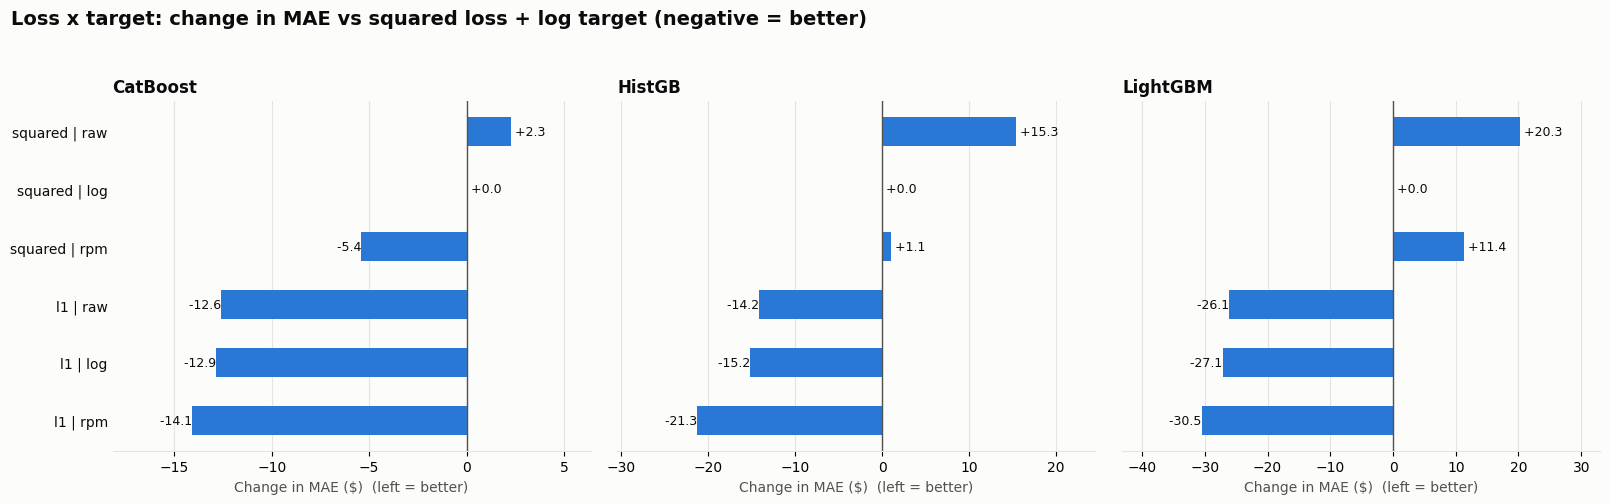

Best combinations


,model,variant,mae,mae_std,medape_%,rmse
17,LightGBM,l1 | rpm,109.83,4.12,2.22,599.07
11,HistGB,l1 | rpm,111.59,4.52,2.29,599.63
5,CatBoost,l1 | rpm,112.34,5.64,2.18,601.42
16,LightGBM,l1 | log,113.18,5.33,2.31,600.52
4,CatBoost,l1 | log,113.55,4.77,2.36,600.95
3,CatBoost,l1 | raw,113.81,4.76,2.38,600.80
15,LightGBM,l1 | raw,114.20,5.84,2.34,600.87
10,HistGB,l1 | log,117.70,6.58,2.48,602.12


In [43]:
# Loss (squared or l1) x target (raw, log or rate per mile) for the three candidate models
from catboost import CatBoostRegressor


def make_model(kind, loss="squared"):
    if kind == "HistGB":
        return HistGradientBoostingRegressor(
            loss="absolute_error" if loss == "l1" else "squared_error", random_state=SEED)
    if kind == "LightGBM":
        return LGBMRegressor(objective="l1" if loss == "l1" else "regression",
                             n_estimators=400, learning_rate=0.05, random_state=SEED, verbose=-1)
    if kind == "CatBoost":
        return CatBoostRegressor(loss_function="MAE" if loss == "l1" else "RMSE",
                                 iterations=500, learning_rate=0.05, random_seed=SEED, verbose=0)
    if kind == "ExtraTrees":
        return ExtraTreesRegressor(n_estimators=200, n_jobs=-1, random_state=SEED)


FINAL3 = ["CatBoost", "HistGB", "LightGBM"]
results = [r for r in results if r["step"] != "1-loss-target"]      # remove earlier results so the cell can be re-run

for kind in FINAL3:
    for loss in ["squared", "l1"]:
        for target in ["raw", "log", "rpm"]:
            run("1-loss-target", f"{loss} | {target}", kind,
                make_est(kind, make_prep(), target=target, loss=loss))
    print(kind, "done")

delta_lt = show("1-loss-target", "squared | log")
plot_delta(delta_lt, "Loss x target: change in MAE vs squared loss + log target (negative = better)")

lt = pd.DataFrame([r for r in results if r["step"] == "1-loss-target"])
print("Best combinations")
display(lt.sort_values("mae")[["model", "variant", "mae", "mae_std", "medape_%", "rmse"]].head(8).round(2))


## Conclusion: l1 loss and rate-per-mile target

**Loss.** The l1 (absolute error) loss is the main gain: the CV MAE drops by 13 to 30 USD for the three models, in the 3 folds each time. It is the metric we want to minimise, and it is not pulled by the random price outliers the way the squared loss is.

**Target.** Training on the rate per mile and predicting price = rate x distance is slightly better than the log or the raw price (1 to 6 USD; 3 folds out of 3 for HistGB and LightGBM, 2 out of 3 for CatBoost). The gain is small and partly noise, but the choice is coherent because the price is roughly rate x distance. The conversion is done inside the model (`RpmTarget.predict`), so the predictions are prices in USD like the labels. Distance is never null or zero (minimum 70 miles).

**Result.** With quote_signal removed, l1 loss and the rate-per-mile target, the three models reach 110 to 112 USD of CV MAE, within noise of each other (std over folds about 4 to 6 USD). Next step: tune each one, then compare them.

## Hyperparameter tuning (random search, 2 stages)

- Same time-ordered CV, metric MAE, l1 loss and rate-per-mile target for the three models.
- Stage 1: 40 random configurations over wide ranges. Stage 2: 20 more, sampled only inside the ranges of the 8 best stage-1 configurations.
- Random search rather than a grid: with several parameters it tries many more distinct values for the same time.
- The tuned MAE is slightly optimistic (best of 60 trials on the same folds). The real check is the held-out Sep-Oct test, used once at the end.

In [44]:
# Random search in two stages for each model: wide ranges, then ranges narrowed to the best trials
# Same setup as before: l1 loss and rate-per-mile target
import time
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

N_COARSE, N_FINE, TOP_K = 40, 20, 8
PREFIX = "regressor__model__"          # RpmTarget -> regressor (Pipeline) -> step "model"

# parameter: (type, low, high)   types: int / log (log scale) / lin / fixed
SPACES = {
    "HistGB": {
        "learning_rate":     ("log", 0.02, 0.3),
        "max_iter":          ("int", 100, 800),
        "max_leaf_nodes":    ("int", 8, 128),
        "min_samples_leaf":  ("int", 10, 200),
        "l2_regularization": ("log", 1e-3, 10),
    },
    "LightGBM": {
        "n_estimators":      ("int", 200, 1200),
        "learning_rate":     ("log", 0.02, 0.2),
        "num_leaves":        ("int", 8, 128),
        "min_child_samples": ("int", 10, 200),
        "subsample":         ("lin", 0.6, 1.0),
        "subsample_freq":    ("fixed", 1, 1),         # needed for `subsample` to be used
        "colsample_bytree":  ("lin", 0.6, 1.0),
        "reg_lambda":        ("log", 1e-3, 10),
    },
    "CatBoost": {
        "iterations":        ("int", 300, 1200),
        "learning_rate":     ("log", 0.02, 0.2),
        "depth":             ("int", 4, 8),
        "l2_leaf_reg":       ("log", 1, 20),
    },
}


def to_dist(kind, lo, hi):
    if lo == hi or kind == "fixed":
        return [lo]
    if kind == "int":
        return randint(lo, hi + 1)
    if kind == "log":
        return loguniform(lo, hi)
    return uniform(lo, hi - lo)                      # "lin"


def search(model_name, spec, n_iter, seed):
    est = make_est(model_name, make_prep(), target="rpm", loss="l1")
    dists = {PREFIX + p: to_dist(*s) for p, s in spec.items()}
    rs = RandomizedSearchCV(est, dists, n_iter=n_iter, cv=splits, scoring="neg_mean_absolute_error",
                            random_state=seed, n_jobs=1, refit=False, error_score="raise")
    return rs.fit(X_dev, y_dev)


def trials_table(rs, stage):
    cv = pd.DataFrame(rs.cv_results_)
    out = pd.DataFrame({"stage": stage, "mae": -cv["mean_test_score"], "mae_std": cv["std_test_score"]})
    for i in range(len(splits)):
        out[f"fold{i}"] = -cv[f"split{i}_test_score"]
    out["params"] = [{k.replace(PREFIX, ""): v for k, v in p.items()} for p in cv["params"]]
    return out


def zoom(spec, rs):
    """Narrow every range to [min, max] of the values used by the TOP_K best trials."""
    cv = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score").head(TOP_K)
    fine = {}
    for p, (kind, lo, hi) in spec.items():
        if kind == "fixed":
            fine[p] = (kind, lo, hi)
            continue
        vals = cv["param_" + PREFIX + p].astype(float)
        fine[p] = (kind, vals.min(), vals.max())
        if kind == "int":
            fine[p] = (kind, int(vals.min()), int(vals.max()))
    return fine


tuned = {}
for name in FINAL3:
    t0 = time.time()
    coarse = search(name, SPACES[name], N_COARSE, SEED)
    fine_spec = zoom(SPACES[name], coarse)
    fine = search(name, fine_spec, N_FINE, SEED + 1)
    trials = pd.concat([trials_table(coarse, "coarse"), trials_table(fine, "fine")], ignore_index=True)
    tuned[name] = {"trials": trials, "fine_spec": fine_spec}
    best = trials.sort_values("mae").iloc[0]
    print(f"{name:<9} done in {(time.time() - t0) / 60:4.1f} min | best CV MAE {best['mae']:.1f} (stage: {best['stage']})")


CatBoost  done in 13.7 min | best CV MAE 107.9 (stage: fine)
HistGB    done in 15.0 min | best CV MAE 109.6 (stage: coarse)
LightGBM  done in  5.8 min | best CV MAE 108.8 (stage: fine)


Tuned vs default (CV MAE in $). The tuned MAE is slightly optimistic: it is the best of many trials on the same folds.


,default MAE,tuned MAE,gain,std over folds,fold0,fold1,fold2
model,,,,,,,
CatBoost,112.34,107.93,4.42,3.68,106.25,113.03,104.49
HistGB,111.59,109.56,2.03,4.47,106.50,115.88,106.30
LightGBM,109.83,108.85,0.99,4.31,107.25,114.73,104.55



CatBoost: 5 best configurations


,stage,mae,mae_std,depth,iterations,l2_leaf_reg,learning_rate
54,fine,107.93,3.68,4,1084,9.7573,0.0520
57,fine,108.83,3.56,4,1001,1.0220,0.0778
38,coarse,108.84,3.96,4,558,1.0210,0.0648
11,coarse,109.27,3.87,5,1076,1.0490,0.0340
47,fine,109.29,3.86,5,693,5.3100,0.0279



HistGB: 5 best configurations


,stage,mae,mae_std,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf
7,coarse,109.56,4.47,0.0339,0.2867,604,10,60
10,coarse,109.73,4.38,0.5457,0.0659,554,51,17
19,coarse,109.77,3.80,0.7004,0.1700,478,12,50
31,coarse,110.06,5.04,0.0028,0.0371,732,123,12
15,coarse,110.07,4.45,0.0200,0.0573,437,118,62



LightGBM: 5 best configurations


,stage,mae,mae_std,colsample_bytree,learning_rate,min_child_samples,n_estimators,num_leaves,reg_lambda,subsample,subsample_freq
40,fine,108.85,4.31,0.6788,0.0543,33,357,44,0.0165,0.8955,1
41,fine,109.02,3.99,0.6652,0.0216,76,1102,78,0.0280,0.6604,1
7,coarse,109.20,4.03,0.8733,0.0815,17,1142,42,4.3379,0.7035,1
39,coarse,109.24,4.32,0.7061,0.0351,47,429,116,0.0885,0.9624,1
6,coarse,109.26,4.20,0.9769,0.0732,18,545,60,0.0084,0.6964,1


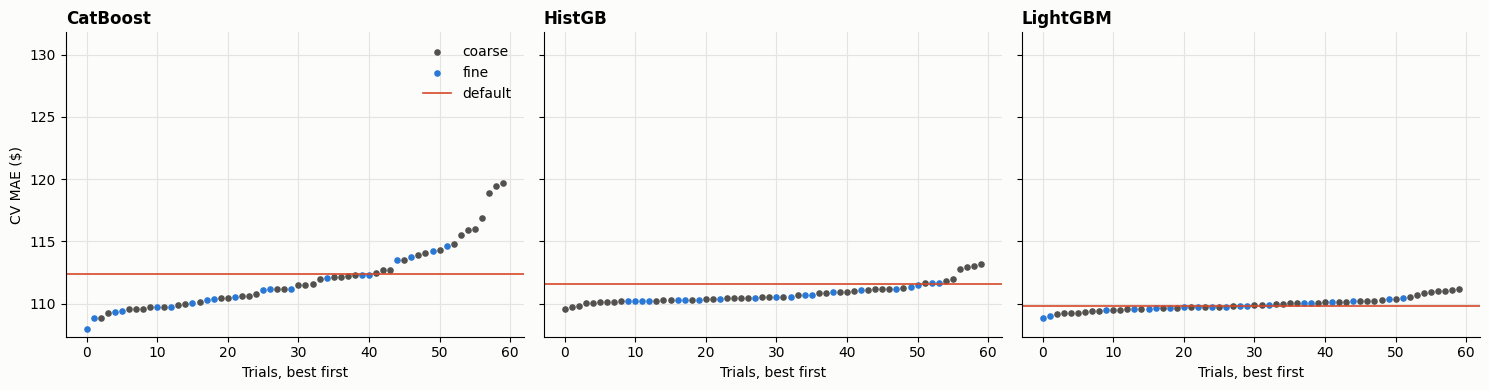

In [45]:
# Tuned vs default MAE, best configurations and trials plot
default_mae = {name: [r for r in results if r["step"] == "1-loss-target"
                      and r["model"] == name and r["variant"] == "l1 | rpm"][0]["mae"]
               for name in FINAL3}

rows = []
for name in FINAL3:
    best = tuned[name]["trials"].sort_values("mae").iloc[0]
    rows.append({"model": name, "default MAE": default_mae[name], "tuned MAE": best["mae"],
                 "gain": default_mae[name] - best["mae"], "std over folds": best["mae_std"],
                 **{f"fold{i}": best[f"fold{i}"] for i in range(len(splits))}})
summary_tuned = pd.DataFrame(rows).set_index("model").round(2)
print("Tuned vs default (CV MAE in $). The tuned MAE is slightly optimistic: it is the best of many trials on the same folds.")
display(summary_tuned)

for name in FINAL3:
    print(f"\n{name}: 5 best configurations")
    top = tuned[name]["trials"].sort_values("mae").head(5)
    display(pd.concat([top[["stage", "mae", "mae_std"]].round(2),
                       pd.DataFrame(list(top["params"]), index=top.index).round(4)], axis=1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, facecolor="#fcfcfb")
for ax, name in zip(axes, FINAL3):
    t = tuned[name]["trials"].sort_values("mae").reset_index(drop=True)
    for stage, color in [("coarse", "#52514e"), ("fine", "#2a78d6")]:
        s = t[t["stage"] == stage]
        ax.scatter(s.index, s["mae"], s=14, color=color, label=stage)
    ax.axhline(default_mae[name], color="#d6492a", linewidth=1.2, label="default")
    ax.set_title(name, loc="left", fontweight="bold")
    ax.set_xlabel("Trials, best first")
    ax.set_ylim(top=default_mae[name] * 1.2)
    ax.set_facecolor("#fcfcfb")
    ax.grid(color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("CV MAE ($)")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()


## Final model and held-out test

The three tuned models are within noise of each other in CV (about 108 to 110 USD of MAE, std over folds about 4 USD). I keep CatBoost: it has the lowest CV MAE and the training time (a few seconds) does not matter here. The held-out Sep-Oct test is used once, only to report the performance.

In [46]:
# Final model: CatBoost, l1 loss, rate-per-mile target, parameters of the best CatBoost trial
FINAL_PARAMS = dict(depth=4, iterations=1084, l2_leaf_reg=9.7573, learning_rate=0.0520)


def final_model():
    est = make_est("CatBoost", make_prep(), target="rpm", loss="l1")
    return est.set_params(**{PREFIX + k: v for k, v in FINAL_PARAMS.items()})


print("final model:", FINAL_PARAMS)


final model: {'depth': 4, 'iterations': 1084, 'l2_leaf_reg': 9.7573, 'learning_rate': 0.052}


,MAE,RMSE,MAPE_%,median_%_error
model,,,,
Baseline: rate/mile by equipment,229.10,670.66,10.49,6.80
"CatBoost, squared loss + log target",162.49,650.08,6.88,4.31
"CatBoost, l1 loss + rate-per-mile",164.58,649.82,6.95,4.44
CatBoost tuned (final),164.58,649.77,6.94,4.44


CV MAE of the final model: 107.9 | MAE on the held-out test: 164.6
Final model, MAE by test month


,MAE,rows
month,,
2025-09,172.0,4670
2025-10,157.5,4853


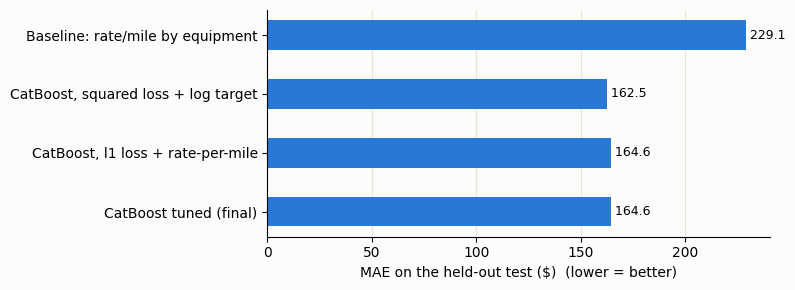

In [47]:
# One evaluation on the held-out test: models are trained on Jan-Aug and scored on Sep-Oct
from sklearn.metrics import mean_absolute_error, mean_squared_error

contenders = {
    "Baseline: rate/mile by equipment":     RatePerMile(by_equipment=True),
    "CatBoost, squared loss + log target":  make_est("CatBoost", make_prep(), target="log", loss="squared"),
    "CatBoost, l1 loss + rate-per-mile":    make_est("CatBoost", make_prep(), target="rpm", loss="l1"),
    "CatBoost tuned (final)":               final_model(),
}

rows, test_pred = [], {}
for name, est in contenders.items():
    est.fit(X_dev, y_dev)
    p = est.predict(X_test)
    test_pred[name] = p
    ape = np.abs(y_test.to_numpy() - p) / y_test.to_numpy()
    rows.append({"model": name,
                 "MAE": mean_absolute_error(y_test, p),
                 "RMSE": np.sqrt(mean_squared_error(y_test, p)),
                 "MAPE_%": ape.mean() * 100,
                 "median_%_error": np.median(ape) * 100})
test_results = pd.DataFrame(rows).set_index("model").round(2)
display(test_results)

cv_best = 107.93   # best CV MAE of the tuned CatBoost, from the tuning table
print(f"CV MAE of the final model: {cv_best:.1f} | MAE on the held-out test: {test_results.loc['CatBoost tuned (final)', 'MAE']:.1f}")

final_name = "CatBoost tuned (final)"
by_month = (pd.DataFrame({"abs_err": np.abs(y_test.to_numpy() - test_pred[final_name]),
                          "month": X_test["date"].dt.strftime("%Y-%m").to_numpy()})
              .groupby("month")["abs_err"].agg(["mean", "count"]).round(1))
by_month.columns = ["MAE", "rows"]
print("Final model, MAE by test month")
display(by_month)

fig, ax = plt.subplots(figsize=(8, 3), facecolor="#fcfcfb")
ax.barh(test_results.index, test_results["MAE"], color="#2a78d6", height=0.5)
for y, v in enumerate(test_results["MAE"]):
    ax.text(v, y, f" {v:.1f}", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("MAE on the held-out test ($)  (lower = better)")
ax.set_facecolor("#fcfcfb")
ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


,bias ($),bias ($ per mile),MAE ($)
CV fold 0,56.994,0.051,65.093
CV fold 1,48.025,0.046,59.841
CV fold 2,41.598,0.038,52.364
Test Sep-Oct,109.130,0.101,109.520


Sep-Oct days sit 0.10 USD per mile above the line fitted on Jan-Aug


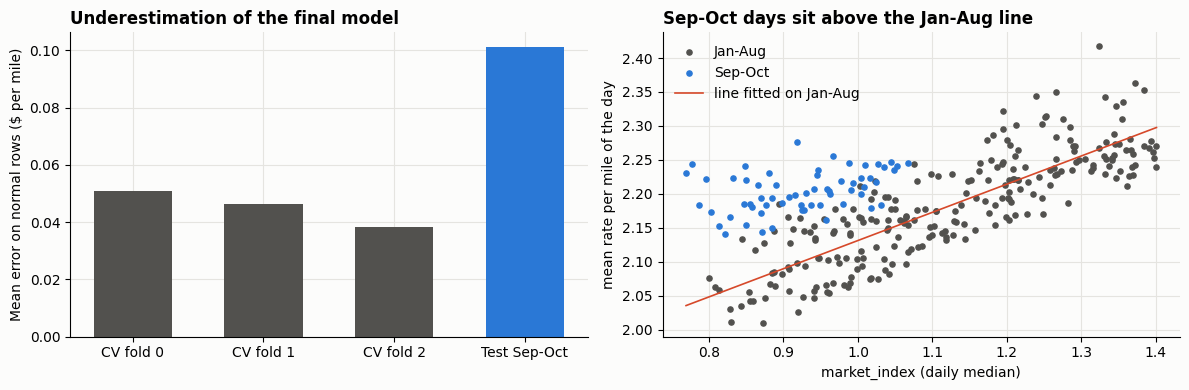

In [57]:
# Level shift in Sep-Oct: bias of the final model on normal rows, and daily market_index vs rate per mile
# Normal rows = rate per mile between 1.5 and 4. Positive bias = the model underestimates the price
def normal_bias(y, pred, X):
    rpm = y.to_numpy() / X["distance"].to_numpy()
    ok = (rpm >= 1.5) & (rpm <= 4)
    err = (y.to_numpy() - pred)[ok]
    return pd.Series({"bias ($)": err.mean(),
                      "bias ($ per mile)": (err / X["distance"].to_numpy()[ok]).mean(),
                      "MAE ($)": np.abs(err).mean()})


bias_rows = {}
for i, (tr, va) in enumerate(splits):
    m = final_model().fit(X_dev.iloc[tr], y_dev.iloc[tr])
    bias_rows[f"CV fold {i}"] = normal_bias(y_dev.iloc[va], m.predict(X_dev.iloc[va]), X_dev.iloc[va])
bias_rows["Test Sep-Oct"] = normal_bias(y_test, test_pred[final_name], X_test)
bias_table = pd.DataFrame(bias_rows).T
display(bias_table.round(3))

rate_per_mile = df["posted_rate"] / df["distance"]
normal = df[rate_per_mile.between(1.5, 4)]
day = (normal.assign(rate_per_mile=rate_per_mile[normal.index])
             .groupby("date")
             .agg(market_index=("market_index", "median"), rate_per_mile=("rate_per_mile", "mean"))
             .reset_index())
recent = day["date"] > cutoff
fit_slope, fit_intercept = np.polyfit(day.loc[~recent, "market_index"], day.loc[~recent, "rate_per_mile"], 1)
gap = (day["rate_per_mile"] - (fit_intercept + fit_slope * day["market_index"]))[recent].mean()
print(f"Sep-Oct days sit {gap:.2f} USD per mile above the line fitted on Jan-Aug")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor="#fcfcfb")
axes[0].bar(bias_table.index, bias_table["bias ($ per mile)"], width=0.6,
            color=["#52514e"] * len(splits) + ["#2a78d6"])
axes[0].set_ylabel("Mean error on normal rows ($ per mile)")
axes[0].set_title("Underestimation of the final model", loc="left", fontweight="bold")
axes[1].scatter(day.loc[~recent, "market_index"], day.loc[~recent, "rate_per_mile"], s=14, color="#52514e", label="Jan-Aug")
axes[1].scatter(day.loc[recent, "market_index"], day.loc[recent, "rate_per_mile"], s=14, color="#2a78d6", label="Sep-Oct")
xs = np.linspace(day["market_index"].min(), day["market_index"].max(), 50)
axes[1].plot(xs, fit_intercept + fit_slope * xs, color="#d6492a", linewidth=1.2, label="line fitted on Jan-Aug")
axes[1].set_xlabel("market_index (daily median)")
axes[1].set_ylabel("mean rate per mile of the day")
axes[1].set_title("Sep-Oct days sit above the Jan-Aug line", loc="left", fontweight="bold")
axes[1].legend(frameon=False)
for ax in axes:
    ax.set_facecolor("#fcfcfb")
    ax.grid(color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Predictions for validation.csv and the December chart

The final model is retrained on all labelled data (Jan-Oct), then used on validation.csv. For the December chart, the coordinates come from the labelled data (fixed for each city) and market_index is the median of the day in validation.csv.

In [ ]:
# Refit on all labelled data (Jan-Oct) and predict validation.csv
# Nothing is evaluated here: validation.csv has no labels
X_all, y_all = df.drop(columns="posted_rate"), df["posted_rate"]
final_est = final_model().fit(X_all, y_all)

val_X = val_df.copy()
val_X["date"] = pd.to_datetime(val_X["date"])
pred_val = final_est.predict(val_X)

template = pd.read_csv("validation-predictions-template.csv")
out = template[["load_id"]].merge(pd.DataFrame({"load_id": val_X["load_id"], "predicted_rate": pred_val}),
                                  on="load_id", how="left")

# same checks as the scorer
assert list(out.columns) == ["load_id", "predicted_rate"]
assert len(out) == 12000 and out["load_id"].is_unique
assert out["predicted_rate"].notna().all() and (out["predicted_rate"] > 0).all()

out.to_csv("validation_predictions.csv", index=False)
print("saved validation_predictions.csv:", out.shape, "| min", round(out["predicted_rate"].min(), 1),
      "| median", round(out["predicted_rate"].median(), 1), "| max", round(out["predicted_rate"].max(), 1))


# Check that the predicted rates per mile look like the labelled ones
chk = val_X.assign(pred=pred_val)
chk["pred_rpm"] = chk["pred"] / chk["distance"]
train_rpm = y_all / X_all["distance"]
q = [0.01, 0.5, 0.99]
compare = pd.DataFrame({"labelled data: rate/mile": train_rpm.quantile(q),
                        "validation: predicted rate/mile": chk["pred_rpm"].quantile(q)}).round(2)
display(compare)
print("mean rate/mile by equipment")
display(pd.DataFrame({"labelled data": train_rpm.groupby(X_all["equipment"]).mean(),
                      "validation (predicted)": chk.groupby("equipment")["pred_rpm"].mean()}).round(2))


saved validation_predictions.csv: (12000, 2) | min 186.8 | median 1995.0 | max 6706.9


,labelled data: rate/mile,validation: predicted rate/mile
0.01,1.67,1.72
0.50,2.15,2.10
0.99,3.18,2.93


mean rate/mile by equipment


,labelled data,validation (predicted)
equipment,,
Dry Van,2.12,2.05
Flatbed,2.29,2.21
Reefer,2.38,2.31


In [ ]:
# Build the December inputs and predict
# december-chart-inputs.csv has no coordinates and no market_index:
#  - coordinates: fixed for each city, taken from the labelled data
#  - market_index: median of the day in validation.csv
# The original file is left unchanged, the completed one is saved as december_predictions.csv
dec = pd.read_csv("december-chart-inputs.csv")
dec_X = dec.drop(columns="predicted_rate").copy()
dec_X["date"] = pd.to_datetime(dec_X["date"])

route = df[(df["pickup"] == "Lexington") & (df["delivery"] == "Fort Wayne")].iloc[0]
for c in ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]:
    dec_X[c] = route[c]

market_by_day = val_X.groupby("date")["market_index"].median()
dec_X["market_index"] = dec_X["date"].map(market_by_day)
assert dec_X["market_index"].notna().all(), "a December day has no market_index in validation.csv"

dec_out = dec.copy()
dec_out["predicted_rate"] = final_est.predict(dec_X)
assert (dec_out["predicted_rate"] > 0).all()
dec_out.to_csv("december_predictions.csv", index=False)

display(dec_out.assign(market_index=dec_X["market_index"].round(3)).head(8))
print("December predicted rate: min", round(dec_out["predicted_rate"].min(), 1),
      "| max", round(dec_out["predicted_rate"].max(), 1))


,pickup,delivery,distance,equipment,weight,date,predicted_rate,market_index
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,808.587642,0.833
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,811.251369,0.915
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,816.078482,0.994
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,819.703354,1.025
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,814.263792,0.975
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,810.514067,0.890
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,808.587642,0.829
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,809.659964,0.840


December predicted rate: min 808.6 | max 821.0


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.
 


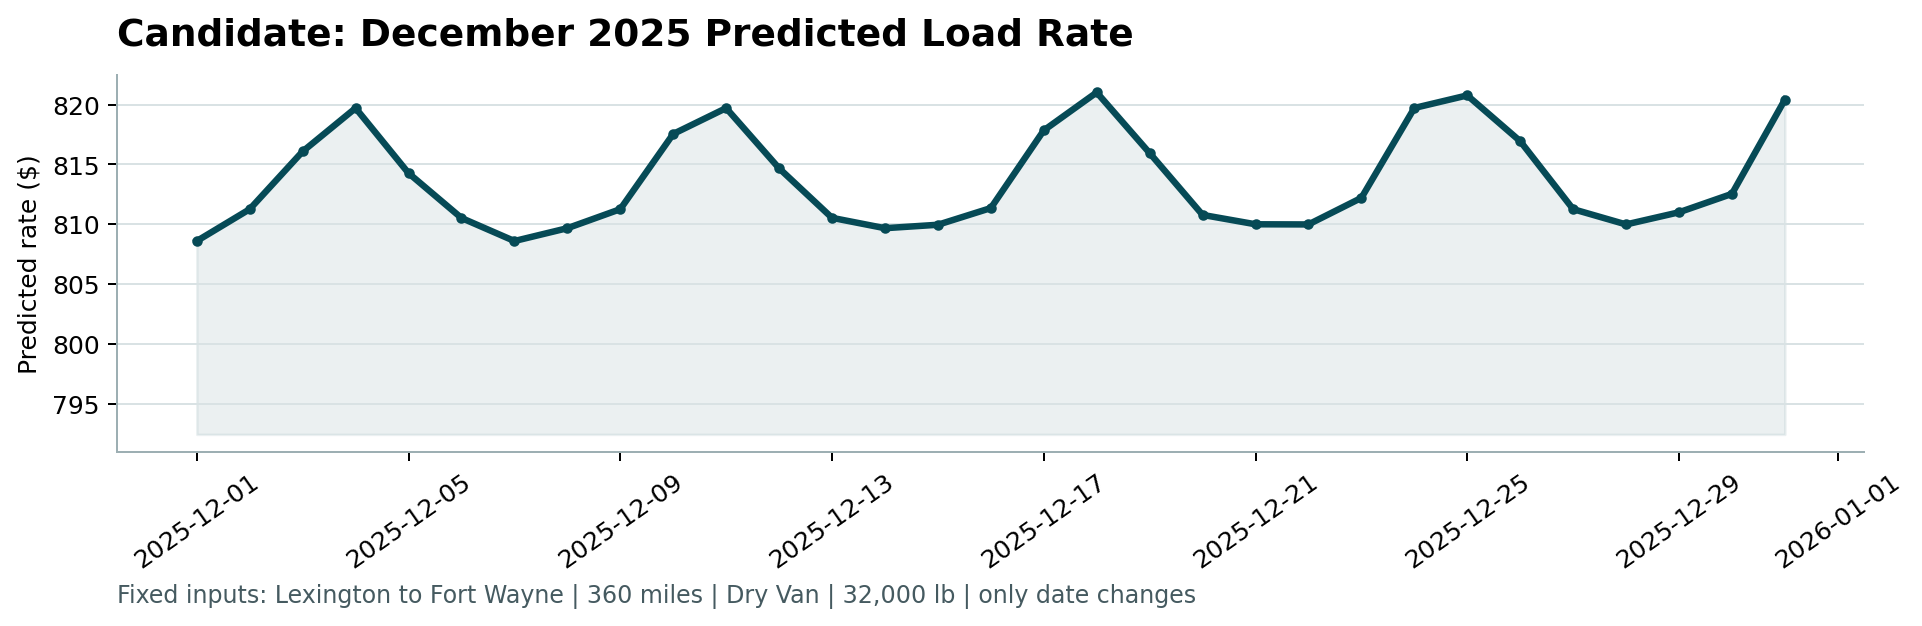

In [ ]:
# Run the provided scorer
import subprocess, sys
from IPython.display import Image, display

r = subprocess.run([sys.executable, "score.py",
                    "--predictions", "validation_predictions.csv",
                    "--december-predictions", "december_predictions.csv"],
                   capture_output=True, text=True)
print(r.stdout, r.stderr)
display(Image("scorer_results/candidate_december.png"))


## Export the trained model

The fitted pipeline (preprocessing and CatBoost, retrained on all labelled data) is saved with joblib, then reloaded to check that it gives exactly the same predictions.

The pipeline uses classes defined in this notebook (`RpmTarget` and the preprocessing transformers). To load the file in another script or session, those class definitions must be available there first.

In [ ]:
# Save the final model and check that it reloads with identical predictions
import os
import joblib

MODEL_PATH = "freight_rate_model.joblib"
joblib.dump(final_est, MODEL_PATH)

reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded.predict(val_X), pred_val)
print(f"saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB), reloaded model gives the same predictions on validation.csv")

saved freight_rate_model.joblib (0.4 MB), reloaded model gives the same predictions on validation.csv


## Summary

| Model | MAE, time-ordered CV (USD) | MAE, held-out Sep-Oct test (USD) |
|---|---|---|
| Baseline: rate per mile by equipment | 206.7 | 229.1 |
| CatBoost, l1 loss, rate-per-mile target, tuned (final) | 107.9 | 164.6 |

- The final model beats the baseline by a wide margin on the held-out months.
- The test MAE is much higher than the CV MAE. On normal rows the model underestimates the price in Sep-Oct (about 0.10 USD per mile, against 0.04 to 0.05 in CV): the price level moved relative to `market_index`. In Sep-Oct the market index is in the lower part of its range, but the days sit above the line fitted on Jan-Aug (right graph above). This is a change in the data, not a lack of model capacity. CV is therefore optimistic, and the test figure is the one to quote.
- Loss, target and tuning improved the CV score but not the held-out score: the CatBoost variants are within noise of each other on the test.
- The final model is retrained on Jan-Oct, so it has seen the Sep-Oct level. Nov-Dec cannot be checked, and the level may have moved again.
- December chart: `december-chart-inputs.csv` has no `market_index`, so the value of each day is the median of that day in `validation.csv`. The curve follows the weekly rhythm of `market_index`. It varies by less than 2% (about 809 to 821 USD), and the y-axis of the chart is zoomed.